# Семинар по теме «Логистическая регрессия, SVM»

На семинаре обучим логистическую регрессию и SVM, сравним их качество и разделяющие границы. Затем проверим калибровку вероятностей и сравним подходы OvR и OvO для многоклассовой классификации.

## Постановка задачи классификации

В этом семинаре мы будем решать задачу бинарной классификации — когда нужно определить, к какому из двух классов относится объект.
Чтобы продемонстрировать работу моделей на реальных данных, используем несколько датасетов.

Первый из них — встроенный датасет `wine` из библиотеки sklearn. Он содержит информацию о химическом составе вин трёх разных сортов, выращенных в одном регионе Италии. У каждого образца есть 13 признаков, например содержание алкоголя, магния, флавоноидов.

Для первых экспериментов оставим четыре признака. Позже сравним их со всеми 13 признаками на одном и том же разбиении данных.

Чтобы прийти к задаче бинарной классификации, возьмём только два сорта вина — те, что обозначены как классы 0 и 1.

Этот датасет — классика при знакомстве с задачей классификации. [Подробнее про датасет wine](https://www.kaggle.com/datasets/hongseoi/uci-wine-dataset-for-classification).

Для начала построим 2D-scatter-график, на котором по осям отложим два первых признака из набора, а цветом покажем принадлежность к классу. Это даст визуальное представление того, насколько классы можно разделить в пространстве признаков.

### Импорт данных и визуализация

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.preprocessing import LabelEncoder

# Загружаем датасет
data = load_wine()
X = data.data
X = data.data[:, [0, 2, 3, 7]]
y = data.target
feature_names = [data.feature_names[i] for i in [0, 2, 3, 7]]

# Оставляем только объекты классов 0 и 1
mask = y < 2
X = X[mask]
y = y[mask]

# Разбиваем данные на обучающую и валидационную выборки
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42)

In [ ]:
import itertools

def plot_feature_pair_distributions(X, y, feature_names):
    # Визуализируем зависимость распределения таргета от признаков попарно

    # Получаем все пары признаков
    feature_pairs = list(itertools.combinations(range(X.shape[1]), 2))

    # Указываем количество графиков в строке
    cols = 4
    rows = (len(feature_pairs) + cols - 1) // cols

    # Создаём сетку подграфиков
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = axes.flatten()  # Преобразуем в одномерный список

    # Рисуем каждый подграфик
    for i, (idx1, idx2) in enumerate(feature_pairs):
        ax = axes[i]
        for class_label, class_name, color in zip([0, 1], ["Класс 0", "Класс 1"], ['blue', 'red']):
            subset = X[y == class_label]
            ax.scatter(
                subset[:, idx1], subset[:, idx2],
                label=class_name if i == 0 else "",
                color=color, edgecolor='k', alpha=0.6
            )
        ax.set_xlabel(feature_names[idx1])
        ax.set_ylabel(feature_names[idx2])
        ax.set_title(f"{feature_names[idx1]} vs {feature_names[idx2]}")
        ax.grid(True)

    # Удаляем лишние подграфики
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    # Легенда и отступы
    if rows * cols > 1:
        axes[0].legend()
    plt.tight_layout()
    plt.show()

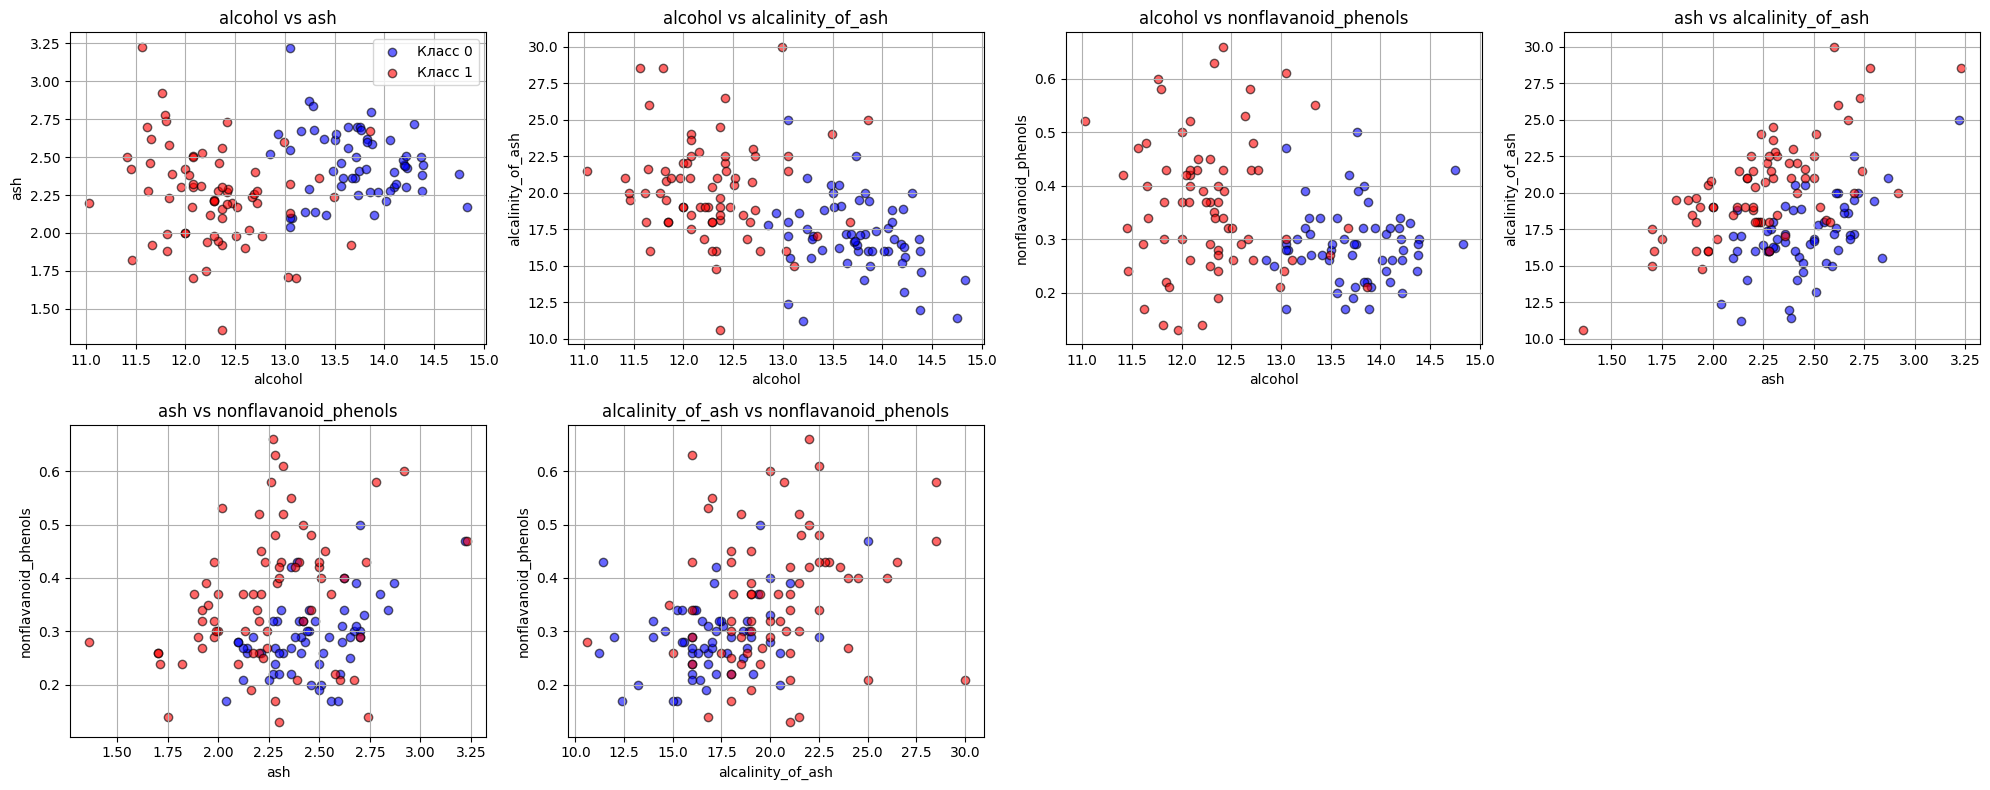

In [ ]:
plot_feature_pair_distributions(X, y, feature_names)

Рассмотрим масштабированные данные.

### Задание 1  

Масштабируй признаки с помощью `StandardScaler` и снова построй scatter-графики. Здесь масштабирование нужно только для иллюстрации. При обучении модели параметры преобразования следует оценивать по обучающей выборке.

**Заготовка для студента**

```python
# Масштабируй данные
# Напиши код здесь

# Выведи 2D-scatter-графики распределения для масштабированных данных
# Напиши код здесь
```

#### Решение

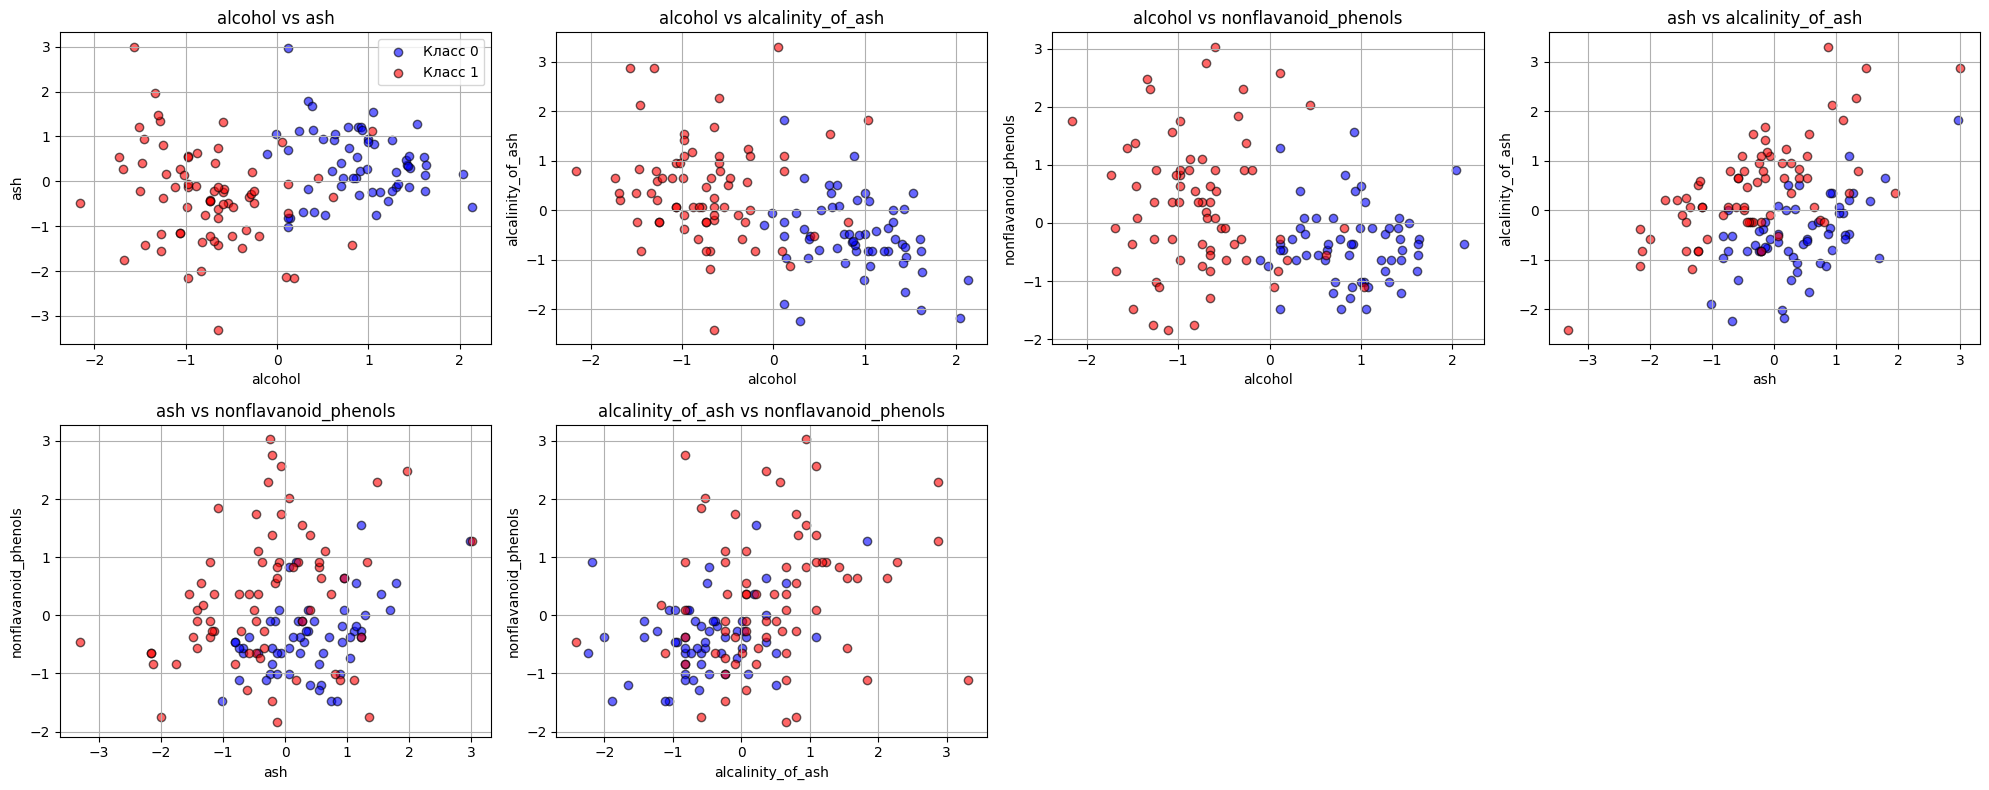

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
plot_feature_pair_distributions(X_scaled, y, feature_names)

**Вопрос.** Почему получились похожие по структуре графики для масштабированных и немасштабированных данных?

**Ответ.** StandardScaler вычитает среднее и делит каждый признак на его стандартное отклонение. Он сдвигает и изменяет масштаб осей, сохраняя структуру облака точек. Автоматический выбор границ осей делает графики внешне похожими даже при разных исходных масштабах.

### Задание 2

Напиши функцию для оценки бинарного классификатора по двум кривым. На вход подавай вероятности или непрерывные оценки положительного класса, а не метки классов.

1. ROC-кривая показывает зависимость TPR от FPR при изменении порога. ROC-AUC лежит в диапазоне от 0 до 1. Значение 0,5 соответствует случайному ранжированию, ниже 0,5 возможно преимущественно обратное ранжирование.
2. PR-кривая показывает зависимость precision от recall. Для неё рассчитай Average Precision (AP), взвешенное среднее precision по приращениям recall. AP отличается от площади, вычисленной методом трапеций. При сравнении учитывай долю положительного класса.

**Заготовка для студента**

```python
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

def plot_model_summary(y_true, y_pred, classifier_name='Some Classifier', ax=None):
    auc_roc = roc_auc_score(y_true, y_pred)
    auc_pr = average_precision_score(y_true, y_pred)

    if ax is None:
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # PR-кривая
    PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax[0], name=classifier_name)
    ax[0].set_title(f"PR-кривая (AP = {auc_pr:.2f})")
    ax[0].grid(True)
    ax[0].set_ylim(0, 1.05)

    # ROC-кривая

    # По аналогии с PR-кривой получи значения и построй ROC-кривую
    # Напиши код здесь
    # Дорисуем пунктирную линию, отображающую случайную модель
    ax[1].plot([0, 1], [0, 1], 'k--', label='случайная модель')

    plt.suptitle(f'Качество модели: {classifier_name}', fontsize=14)
    plt.tight_layout()
    plt.show()
```

#### Решение

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

def plot_model_summary(y_true, y_pred, classifier_name='Some Classifier', ax=None):
    auc_roc = roc_auc_score(y_true, y_pred)
    auc_pr = average_precision_score(y_true, y_pred)

    if ax is None:
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # PR-кривая
    PrecisionRecallDisplay.from_predictions(y_true, y_pred, ax=ax[0], name=classifier_name)
    ax[0].set_title(f"PR-кривая (AP = {auc_pr:.2f})")
    ax[0].grid(True)
    ax[0].set_ylim(0, 1.05)

    # ROC-кривая
    RocCurveDisplay.from_predictions(y_true, y_pred, ax=ax[1], name=classifier_name)
    ax[1].plot([0, 1], [0, 1], 'k--', label='случайная модель')
    ax[1].grid(True)
    ax[1].set_ylim(0, 1.05)
    ax[1].set_title(f"ROC-кривая (AUC = {auc_roc:.2f})")


    plt.suptitle(f'Качество модели: {classifier_name}', fontsize=14)
    plt.tight_layout()
    plt.show()

Создадим таблицу для сравнения метрик моделей.

In [ ]:
import pandas as pd

metrics_accumulated = pd.DataFrame(columns=['AP (качество по Precision/Recall)',
    'AUC-ROC (качество по ROC-кривой)',
    'Параметр модели',
    'Значение параметра'
])

## Логистическая регрессия

Логистическая регрессия оценивает вероятность положительного класса:

$$p(y=1\mid x)=\sigma(w^\top x+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.$$

Здесь $w$ содержит коэффициенты признаков, а $b$ является свободным членом. Например, значение 0,8 означает оценку вероятности класса 1, равную 80%. Для получения метки класса эту оценку сравнивают с порогом, обычно 0,5.

Для меток $y_i\in\{-1,+1\}$ минимизируют логистическую потерю:

$$L(w,b)=\sum_{i=1}^{n}\log\left(1+\exp[-y_i(w^\top x_i+b)]\right).$$

Это отрицательное логарифмическое правдоподобие наблюдаемых меток. В sklearn бинарные метки можно задавать числами 0 и 1. Вероятность положительного класса для конкретного объекта отличается от доли верных ответов модели.

### Задание 3

Обучи логистическую регрессию на основе датасета `wine` и получи предсказания.
>Если вызвать логистическую регрессию без указания дополнительных аргументов, гиперпараметру $C$ присваивается значение 1.
 Параметр $C$ контролирует степень регуляризации модели — насколько сильно модель штрафуется за слишком большие веса (сложность):
* чем меньше $C$, тем модель проще;
* чем больше $C$, тем слабее регуляризация — модель может быть сложнее и подстраиваться под данные.

Метод `.predict_proba()` в моделях sklearn возвращает вероятности принадлежности объекта к каждому классу.
Например, для задачи бинарной классификации (классы 0 и 1) результатом будет массив из двух столбцов:
- первый — вероятность класса 0;
- второй — вероятность класса 1.

Чтобы получить вероятность положительного класса (1), нужно взять второй столбец: [:, 1].

**Важно.** Не все модели в sklearn поддерживают `predict_proba()`.

Сохрани AP и ROC-AUC базовой модели в `metrics_accumulated`, чтобы затем сравнить их с подобранным C.

**Заготовка для студента**

```python
from sklearn.linear_model import LogisticRegression

# Обучи базовую модель логистической регрессии
model_logreg = # Напиши код здесь

# Получаем вероятность положительного класса (1)
y_pred_logreg = # Напиши код здесь

# Визуализируем качество модели
plot_model_summary(y_val, y_pred_logreg, 'ЛогРег (дефолт)')
```

#### Решение

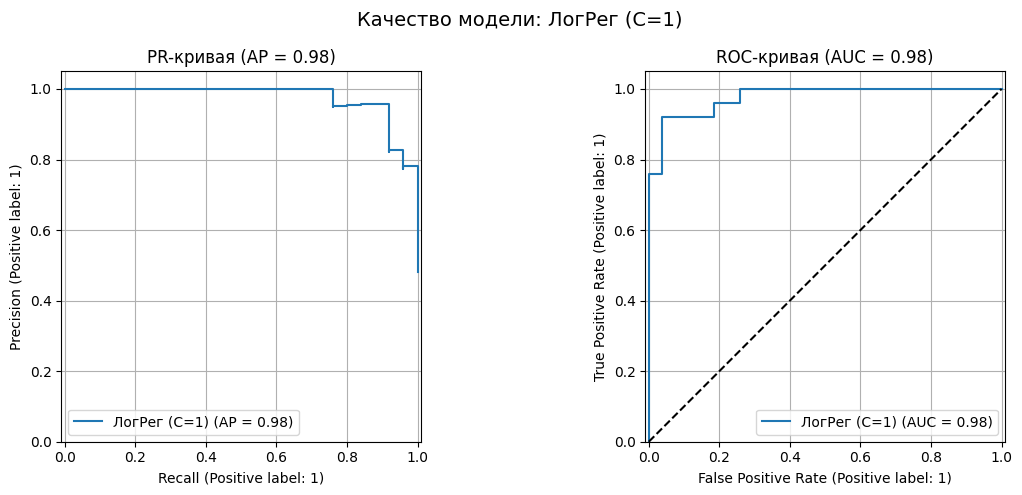

In [ ]:
from sklearn.linear_model import LogisticRegression

# Обучим базовую модель логистической регрессии
model_logreg = LogisticRegression(max_iter=1000)
model_logreg.fit(X_train, y_train)

# Получаем вероятность положительного класса (1)
y_pred_logreg = model_logreg.predict_proba(X_val)[:, 1]

# Визуализируем качество модели
plot_model_summary(y_val, y_pred_logreg, 'ЛогРег (C=1)')
metrics_accumulated.loc['Логистическая регрессия (C=1)'] = [
    average_precision_score(y_val, y_pred_logreg),
    roc_auc_score(y_val, y_pred_logreg), 'C', model_logreg.C
]

Сохраним результат базовой модели и подберём C по кросс-валидации на train. Сравнение нескольких разбиений снижает зависимость выбора C от одного разбиения.

### Подбор гиперпараметра $С$

Проанализируем, как параметр $С$ влияет на качество модели.

Функция `C_param_by_CV` подбирает оптимальное значение гиперпараметра регуляризации $C$ для модели SVM или логистической регрессии, используя кросс-валидацию.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

def C_param_by_CV(X_train, y_train, model_type='SVM'):
    """
    Производит подбор гиперпараметра регуляризации C для:
    - 'SVM': SVM с линейным ядром
    - 'log_reg': логистическая регрессия с L2-регуляризацией

    Возвращает лучшее значение C по метрике Average Precision (AP)
    """
    if model_type == 'SVM':
        estimator = SVC(kernel="linear", random_state=42, probability=True)
    elif model_type == 'log_reg':
        estimator = LogisticRegression(max_iter=10000)
    else:
        raise ValueError("model_type должен быть SVM или log_reg")

    # Подбираем параметр регуляризации C на логарифмической шкале:
    # от 10^(-2,3) ≈ 0,005 до 10^(-1,3) ≈ 0,05, всего 100 значений
    # Это помогает найти наилучший уровень регуляризации без резких скачков
    parameters = {'C': np.logspace(-2.3, -1.3, 100)}

    # GridSearch по Average Precision с кросс-валидацией
    grid_search = GridSearchCV(
        estimator=estimator,            # Модель, параметры которой мы подбираем (например, логистическая регрессия)
        param_grid=parameters,          # Словарь параметров для перебора (в нашем случае — разные значения C)
        scoring='average_precision',    # Метрика, по которой выбирается лучшая модель (AP — взвешенное среднее precision по приращениям recall)
        cv=10,                          # Количество фолдов в кросс-валидации (здесь 10)
        n_jobs=-1                       # Использовать все доступные ядра процессора (ускоряет перебор)
    )

    # Обучение моделей на разных C
    grid_search.fit(X_train, y_train)

    best_C = grid_search.best_params_['C']
    print(f"best AP = {grid_search.best_score_:.4f} with C = {best_C:.4f}")

    return best_C

#### Задание 4
Рассчитай лучший параметр $С$ и обучи модель.

**Заготовка для студента**

```python
# Рассчитываем лучший параметр С и обучаем модель
best_C = C_param_by_CV(X_train, y_train, model_type = 'log_reg')

# Обучи модель с параметром С и рассчитай новые вероятности
# Напиши код здесь

# Отрисуем и занесём в таблицу
plot_model_summary(y_val, y_pred_logreg, 'ЛогРег (best C by CV)')
metrics_accumulated.loc['Логистическая регрессия (best C by CV)'] = [
    average_precision_score(y_val, y_pred_logreg),
    roc_auc_score(y_val, y_pred_logreg),
    'C',
    model_logreg.C
]

metrics_accumulated
```

#### Решение

best AP = 0.9695 with C = 0.0446


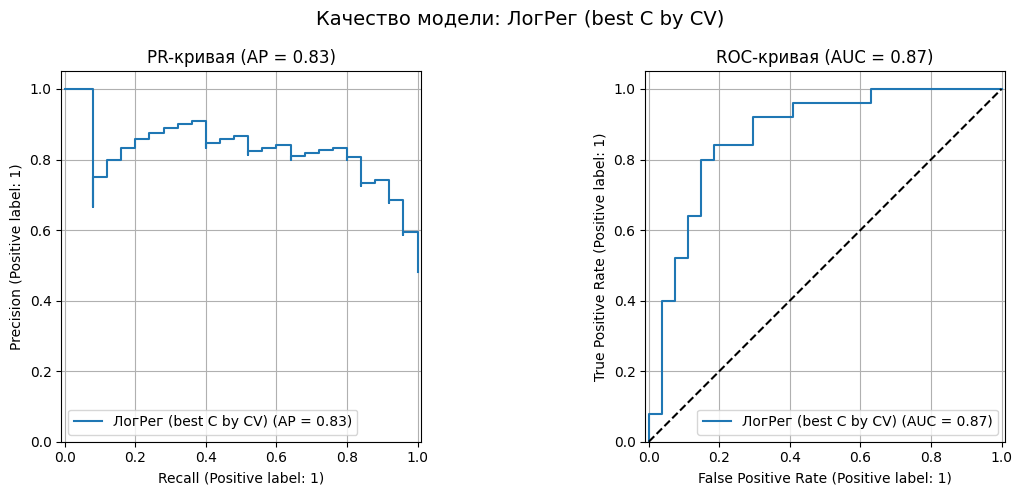

,AP (качество по Precision/Recall),AUC-ROC (качество по ROC-кривой),Параметр модели,Значение параметра
Логистическая регрессия (C=1),0.977225,0.976296,C,1.000000
Логистическая регрессия (best C by CV),0.829337,0.869630,C,0.044616


In [ ]:
# Рассчитываем лучший параметр С и обучаем модель
best_C = C_param_by_CV(X_train, y_train, model_type = 'log_reg')

# Обучи модель с параметром С и рассчитай новые вероятности
model_logreg = LogisticRegression(C=best_C, max_iter=10000)
model_logreg.fit(X_train, y_train)
y_pred_logreg = model_logreg.predict_proba(X_val)[:, 1]

# Отрисуем и занесём в табличку
plot_model_summary(y_val, y_pred_logreg, 'ЛогРег (best C by CV)')
metrics_accumulated.loc['Логистическая регрессия (best C by CV)'] = [
    average_precision_score(y_val, y_pred_logreg),
    roc_auc_score(y_val, y_pred_logreg),
    'C',
    model_logreg.C
]

metrics_accumulated

Сравни AP и ROC-AUC базовой модели и модели с выбранным C. Лучший результат на кросс-валидации может оказаться хуже на отдельной отложенной выборке. Уменьшение C усиливает регуляризацию, но само по себе не доказывает улучшения обобщения.

**Для преподавателя.** В контрольном запуске C по CV около 0,0446. AP на validation снизился с 0,977 до 0,829, ROC-AUC с 0,976 до 0,870. Поэтому здесь подбор C по CV не улучшил результат на отложенной выборке.

#### Влияние параметра C на качество модели

Построим метрики для нескольких C. Поскольку эта выборка используется для сравнения вариантов, далее называем её валидационной. Итоговую независимую тестовую оценку в этом разделе не проводим.

In [ ]:
from sklearn.base import clone

def quality_by_C(X_train, X_val, y_train, y_val, model, param_range=(-3, 3)):
    # Лог-сетка значений С
    C_values = np.logspace(param_range[0], param_range[1], 20)
    roc_scores = []
    pr_scores = []

    for c in C_values:
        # Клонируем модель с текущим C
        current_model = clone(model)
        current_model.set_params(C=c)

        # Обучаем, предсказываем, считаем метрики
        current_model.fit(X_train, y_train)
        y_proba = current_model.predict_proba(X_val)[:, 1]
        roc_scores.append(roc_auc_score(y_val, y_proba))
        pr_scores.append(average_precision_score(y_val, y_proba))

    plt.figure(figsize=(12, 6))

    # ROC-AUC
    plt.subplot(1, 2, 1)
    plt.semilogx(C_values, roc_scores, 'b-o', label='Validation ROC-AUC')
    plt.xlabel('Значение C (Log Scale)')
    plt.ylabel('ROC-AUC')
    plt.title('Зависимость ROC-AUC от C')
    plt.grid(True)
    plt.legend()

    # AP
    plt.subplot(1, 2, 2)
    plt.semilogx(C_values, pr_scores, 'r-o', label='Validation AP')
    plt.xlabel('Значение C (Log Scale)')
    plt.ylabel('AP')
    plt.title('Зависимость AP от C')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

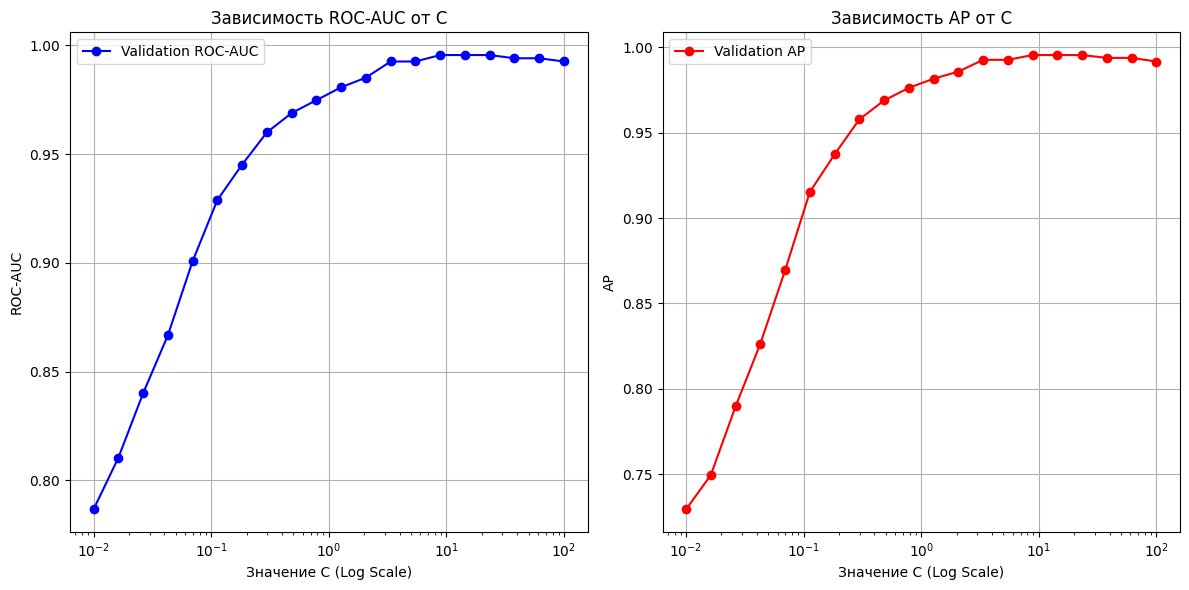

In [ ]:
model = LogisticRegression(max_iter=10000)
quality_by_C(X_train, X_val, y_train, y_val, model, param_range=(-2, 2))

При малом C штраф за большие коэффициенты сильнее, и модель может недообучаться. При увеличении C сравнивай обе метрики на графике. Отдельное снижение валидационной метрики может быть следствием переобучения или вариативности оценки на небольшой выборке.

#### Влияние количества признаков и параметра $С$ на модель

До этого момента мы работали только с четырьмя признаками из датасета. Однако только для следующего анализа мы временно используем все 13 признаков, чтобы оценить, как увеличение размерности признакового пространства влияет на поведение модели при разных значениях $C$.

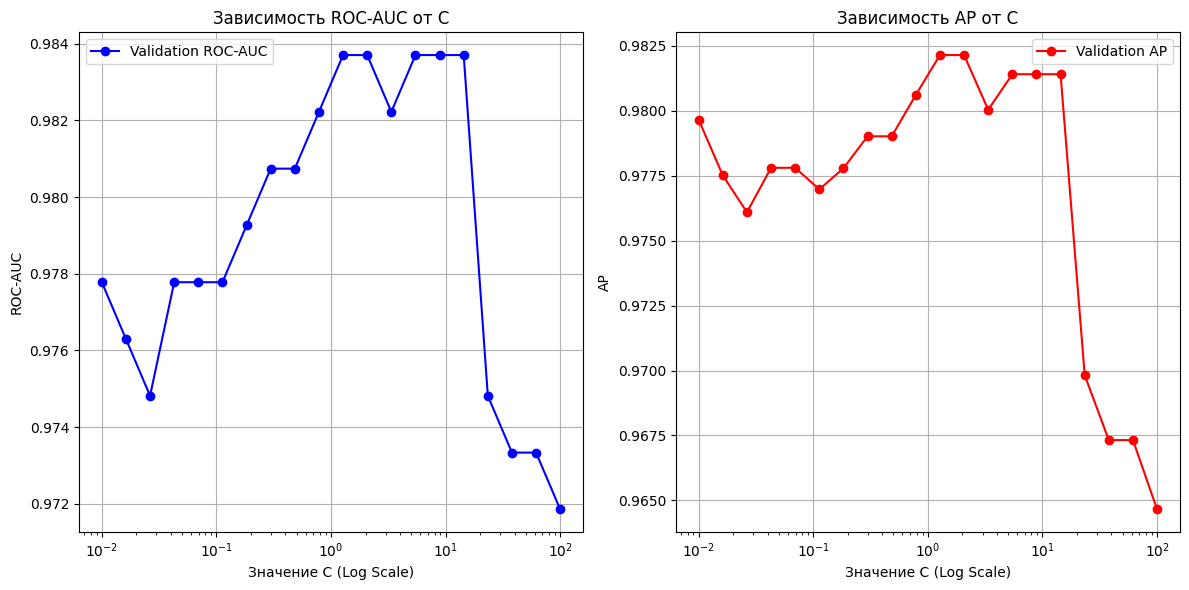

In [ ]:
X_full = data.data
y = data.target
mask = y < 2
X_full = X_full[mask]
y = y[mask]

model = LogisticRegression(max_iter=10000)

X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(X_full, y, test_size=0.4, random_state=42)
quality_by_C(X_train_full, X_val_full, y_train_full, y_val_full, model, param_range=(-2, 2))

Сравни графики для четырёх и 13 признаков на одинаковом разбиении. Дополнительные информативные признаки могут улучшить качество, а шумовые признаки могут усилить переобучение.

**Для преподавателя.** С 13 признаками метрики уже высоки при малом C. Зависимость от C слабее, чем с четырьмя признаками. При больших C виден спад, особенно по AP. Дополнительные признаки полезны в части диапазона C, но увеличение их числа само по себе не устраняет переобучение.

Число признаков само по себе не определяет склонность к переобучению. При сравнении наборов признаков сохраняй одинаковые объекты train и validation, а C выбирай по кросс-валидации.

### Другие гиперпараметры

В sklearn можно задавать другие параметры логистической регрессии.
- `penalty` — отвечает за тип регуляризации. Обычно используется `'l2'`, но, если хотим, чтобы модель использовала меньше признаков (разреженность), можно попробовать `'l1'`.
- `solver` — определяет, каким способом будет обучаться модель. Если не трогать тип регуляризации, менять его не нужно. Для `'l1'` подходят, например, `'liblinear'` и `'saga'`.
- `max_iter` — число итераций, за которое модель должна сойтись. При `ConvergenceWarning` проверь масштаб признаков, solver и достаточность числа итераций.
- `fit_intercept` — определяет, добавлять ли свободный член в модель. Почти всегда он нужен, поэтому оставляем дефолтное `True`.
- `class_weight` — полезен при несбалансированных классах. Например, если один класс встречается в 10 раз реже, можно задать `class_weight='balanced'`, и модель будет учитывать это при обучении.

### Анализ модели: что можно посмотреть после обучения

#### Значения коэффициентов

При фиксированных остальных признаках положительный коэффициент повышает оценку вероятности класса 1, а отрицательный понижает её. Размер коэффициента зависит от единиц измерения признака.

Шансы класса 1 равны $p/(1-p)$. При увеличении признака $j$ на единицу они умножаются на $\exp(w_j)$. Например, `odds_ratio = 2` означает удвоение шансов, а не вероятности.

In [ ]:
# Вытаскиваем пару: название коэффициента и его значение
coefs = pd.Series(model_logreg.coef_[0], index=feature_names)
# Считаем Odds Ratio
odds_ratio = np.exp(model_logreg.coef_[0])

# Создаём DataFrame с коэффициентами и названиями признаков
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model_logreg.coef_[0],
    'Odds_Ratio': np.exp(model_logreg.coef_[0])
})

print(coef_df)

                Feature  Coefficient  Odds_Ratio
0               alcohol    -0.573052    0.563802
1                   ash    -0.168921    0.844576
2     alcalinity_of_ash     0.330815    1.392103
3  nonflavanoid_phenols     0.040801    1.041645


**Вопрос.** Почему интерпретировать рассчитанный показатель `Odds_Ratio` сложнее при масштабированных данных?

**Ответ.** `Odds Ratio`  показывает, во сколько раз изменяются шансы события при увеличении этого признака на один единичный шаг.
Однако, если признаки были масштабированы (например, стандартизированы — вычтено среднее и поделено на стандартное отклонение), то «один шаг» теперь — это не «одна единица исходной измеримой величины», а один стандартный (или другой масштабированный) шаг.

Из-за этого интерпретация OR становится менее интуитивной.
- Мы уже не говорим «увеличение на 1 доллар», «увеличение на 1 год» или «на 1 градус», а «увеличение на 1 стандартное отклонение признака».
- Поэтому понять, что именно означает изменение шансов в терминах исходных данных, сложнее.

#### Кривая обучения (Learning Curve)

Кривая обучения показывает качество на train и validation при разных размерах train. Большой разрыв помогает заметить переобучение, а низкое качество обеих кривых может указывать на недообучение. Рост валидационной метрики при добавлении объектов даёт основание проверить пользу дополнительных данных. Плато на рассмотренных размерах выборки не исключает дальнейшего улучшения.

Построим кривую обучения логистической регрессии, чтобы оценить, как меняется качество модели (ROC-AUC) при увеличении объёма обучающих данных.

/private/tmp/week5-review-20261003/venv/lib/python3.9/site-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
10 fits failed out of a total of 25.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "/private/tmp/week5-review-20261003/venv/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/private/tmp/week5-review-20261003/venv/lib/python3.9/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/private/tmp/week5-review-20261003/venv/lib/python3.9/site-packages/sklearn/linear_mod

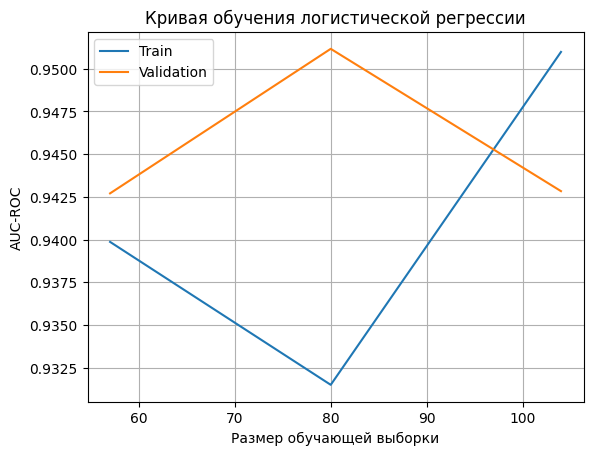

In [ ]:
from sklearn.model_selection import learning_curve

# Строим кривые обучения: модель обучается на разных объёмах данных
train_sizes, train_scores, val_scores = learning_curve(
    model_logreg,
    X,
    y,
    cv=5,
    scoring='roc_auc'
)

# Вычисляем среднее значение метрики по фолдам
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Визуализация
plt.plot(train_sizes, train_mean, label='Train')
plt.plot(train_sizes, val_mean, label='Validation')
# plt.ylim(0, 1)
plt.xlabel("Размер обучающей выборки")
plt.ylabel("AUC-ROC")
plt.title("Кривая обучения логистической регрессии")
plt.legend()
plt.grid(True)
plt.show()

В исходных данных объекты упорядочены по классам. `learning_curve` берёт начальные части обучающих фолдов, и в маленькую часть может попасть только один класс. Поэтому появляются предупреждения и неопределённые значения ROC-AUC.

### Задание 5

Модифицируй код построения кривой обучения так, чтобы предупреждения исчезли. Подсказка: в `learning_curve` можно задать, на каких долях от обучающей выборки тренируется модель. Попробуй увеличить минимальную долю.

**Заготовка для студента**

```python
# Напиши код здесь
```

#### Решение

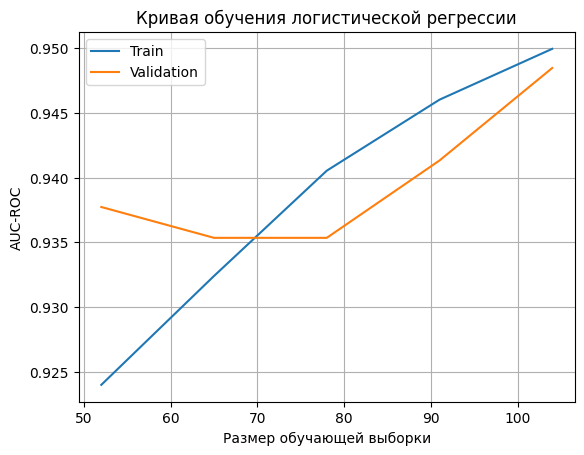

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import learning_curve

# Используем стратифицированную кросс-валидацию,
# чтобы в каждом разбиении сохранялось распределение классов
# Для малых подвыборок дополнительно нужны перемешивание и достаточный размер.

# Строим кривые обучения: модель обучается на разных объёмах данных
train_sizes, train_scores, val_scores = learning_curve(
    model_logreg,
    X,
    y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    shuffle=True,
    random_state=42,
    scoring='roc_auc',
    train_sizes = np.linspace(0.5, 1.0, 5)
)
# Вычисляем среднее значение метрики по фолдам
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Визуализация
plt.plot(train_sizes, train_mean, label='Train')
plt.plot(train_sizes, val_mean, label='Validation')
plt.xlabel("Размер обучающей выборки")
plt.ylabel("AUC-ROC")
plt.title("Кривая обучения логистической регрессии")
plt.legend()
plt.grid(True)
plt.show()

Сравни значения ROC-AUC и разрыв между train и validation. Близость кривых полезна для диагностики только вместе с уровнем качества. По этому графику нельзя точно предсказать выигрыш от сбора новых данных.

**Для преподавателя.** На правом краю исправленного графика средний ROC-AUC около 0,950 на train и 0,949 на validation. Разрыв мал. На меньших подвыборках значения менее устойчивы, и validation местами выше train. На маленькой выборке это возможно из-за состава фолдов.

### Визуализация разделяющей границы логистической регрессии

Для рисунка выберем два признака и обучим на них отдельную модель. Это новая двумерная модель, а не проекция границы модели со всеми признаками.

Поскольку исходные признаки имеют разные масштабы, ранжируем их по $|w_j|s_j$, где $s_j$ является стандартным отклонением признака на train. Эта величина описывает изменение логита при изменении признака на одно стандартное отклонение с фиксированными остальными признаками. Она не является универсальной оценкой важности.

In [ ]:
def plot_logreg_boundary(X, y, model, names):

    # Создаём сетку для визуализации
    xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    yy = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
    XX, YY = np.meshgrid(xx, yy)  # Координатная сетка
    grid = np.c_[XX.ravel(), YY.ravel()]  # Превращаем в (n, 2)

    # Вычисляем вероятности принадлежности к классу +1
    probs = model.predict_proba(grid)[:, 1]
    probs = probs.reshape(XX.shape)

    # Отображаем вероятности как фоновую карту
    plt.figure(figsize=(8, 6))
    contour = plt.imshow(
        probs,
        extent=(xx.min(), xx.max(), yy.min(), yy.max()),
        origin="lower",
        aspect="auto",
        cmap=plt.cm.PuOr,
        alpha=0.8, vmin=0, vmax=1,
    )

    # Отображаем обучающие точки
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors="k")

    plt.colorbar(contour, label="P(y=1 | x)")
    plt.title("Визуализация границы разделения")
    plt.contour(XX, YY, probs, levels=[0.5], colors="black")
    plt.xlabel(names[0])
    plt.ylabel(names[1])
    plt.grid(True)
    plt.show()

**Заготовка для студента**

```python
# Если признаков >2, выбери два самых важных

# Умножь модули коэффициентов на стандартные отклонения признаков на train
# Напиши код здесь

# Выбери два наибольших значения полученной оценки
# Напиши код здесь
top2_idx =

X_2d = X_train[:, top2_idx]
model_2d = LogisticRegression(max_iter=10000).fit(X_2d, y_train)

plot_logreg_boundary(X_2d, y_train, model_2d, [feature_names[j] for j in top2_idx])
```

#### Решение

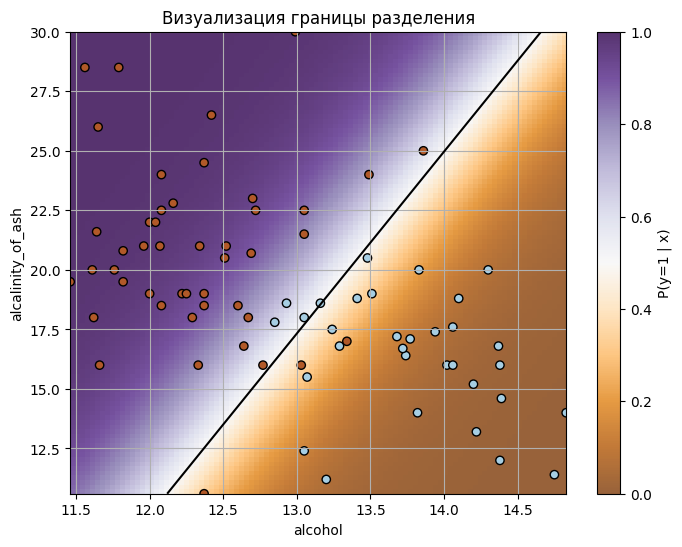

In [ ]:
# Если признаков >2, отбираем два самых важных
feature_importance = np.abs(model_logreg.coef_[0]) * X_train.std(axis=0)
top2_idx = np.argsort(feature_importance)[-2:]
X_2d = X_train[:, top2_idx]
model_2d = LogisticRegression(max_iter=10000).fit(X_2d, y_train)

plot_logreg_boundary(X_2d, y_train, model_2d, [feature_names[j] for j in top2_idx])

На фоне показана вероятность класса 1: оранжевый соответствует низким значениям, фиолетовый высоким. Шкала зафиксирована от 0 до 1. Чёрная линия отмечает вероятность 0,5 и границу классификации при таком пороге.

## SVM

### Краткая теория

>**Support Vector Machine** (SVM) — алгоритм классификации, который ищет гиперплоскость, максимально увеличивающую отступ (Margin) между объектами двух классов.

**Основные формулы**

1. Гиперплоскость разделения:
$  w \cdot x + b = 0, $
  
- где $w$ — вектор весов (нормаль к гиперплоскости);
- $x$ — вектор признаков;
- $b$ — смещение.

2. В линейно разделимом случае опорные векторы лежат на границах зазора:
$$  w \cdot x_i + b = \pm 1.$$

3. Расстояние от точки до гиперплоскости:

$$ \displaystyle \frac{|w \cdot x_i + b|}{\|w\|}.$$

4. Ширина зазора между классами:

$$  \displaystyle \text{Margin} = \frac{2}{\|w\|}. $$

5. Максимизация зазора эквивалентна минимизации нормы весов:

$$  \displaystyle \min_{w, b} \frac{1}{2} \|w\|^2$$

при условии $ y_i(w \cdot x_i + b) \ge 1, \quad \forall i.$



**SVM при линейно неразделимых классах**

Чтобы учесть линейную неразделимость в реальных данных, добавляют $\xi_i$ — параметр ошибок.

Новое условие:

$  y_i(w \cdot x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0. $

Интуиция:

При минимальных допустимых значениях slack-переменных:
- $\xi_i = 0$: точка на границе зазора или за его пределами.
- $0 < \xi_i < 1$: точка внутри зазора, но классифицирована верно.
- $\xi_i = 1$: точка на разделяющей гиперплоскости.
- $\xi_i > 1$: точка классифицирована неверно.

В soft-margin SVM опорные векторы могут находиться и внутри зазора, включая ошибочно классифицированные точки.

**Финальная оптимизационная задача**

$$ \begin{cases} \displaystyle \min_{w, b, \xi} \quad \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{\ell} \xi_i, \\ y_i(w \cdot x_i + b) \ge 1 - \xi_i, \quad \xi_i \ge 0. \end{cases} $$

Альтернативная форма через Hinge Loss:

$$ \displaystyle \min_{w, b}, \quad \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{\ell} \max(0,~1 - y_i(w \cdot x_i + b)),$$

где $C$ — параметр регуляризации:

При увеличении C суммарные нарушения отступа сильнее штрафуются относительно нормы весов. При уменьшении C большее значение получает ширина зазора. Число ошибок классификации при этом не обязано меняться монотонно. В этих формулах метки принимают значения −1 и +1.

### Обучение модели SVM

Обучим SVM на основе датасета `wine`, получим предсказания и сравним результаты обучения с логистической регрессией.

best AP = 0.9883 with C = 0.0501


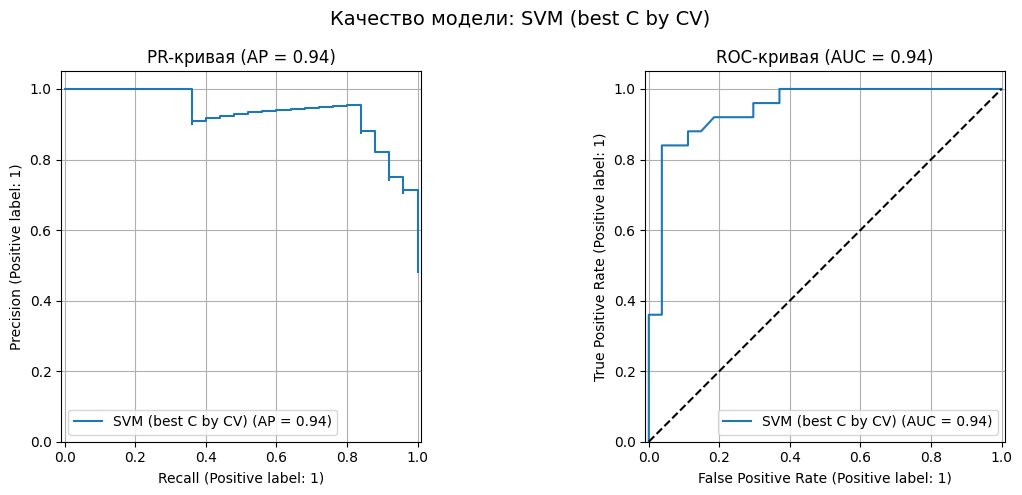

,AP (качество по Precision/Recall),AUC-ROC (качество по ROC-кривой),Параметр модели,Значение параметра
Логистическая регрессия (C=1),0.977225,0.976296,C,1.000000
Логистическая регрессия (best C by CV),0.829337,0.869630,C,0.044616
SVM (best C by CV),0.936155,0.944444,C,0.050119


In [ ]:
from sklearn.svm import SVC

# Рассчитываем лучший параметр C и обучаем модель
best_C = C_param_by_CV(X_train, y_train, model_type='SVM')
model_svm = SVC(probability=True, kernel = 'linear', C=best_C, random_state=42)
model_svm.fit(X_train, y_train)
y_pred_svm = model_svm.predict_proba(X_val)[:, 1]

# Отрисовываем и заносим в таблицу
plot_model_summary(y_val, y_pred_svm, 'SVM (best C by CV)')
metrics_accumulated.loc['SVM (best C by CV)'] = [
    average_precision_score(y_val, y_pred_svm),
    roc_auc_score(y_val, y_pred_svm),
    'C',
    model_svm.C
]

metrics_accumulated

**Вопрос.** Сравни AP и ROC-AUC логистической регрессии и SVM. Совпадает ли их ранжирование по двум метрикам?

**Ответ.** На этом разбиении ранжирование совпадает: базовая логистическая регрессия (AP 0,977, ROC-AUC 0,976), затем SVM с выбранным C (0,936 и 0,944), затем логистическая регрессия с выбранным C (0,829 и 0,870). Подбор по CV не улучшил результат на этой небольшой validation. Логистическая регрессия и SVM оптимизируют разные потери, поэтому их границы могут различаться. Само устройство SVM не гарантирует превосходства по этим метрикам.

Также в `sklearn.svm.SVC` можно задавать другие параметры обучения SVM.

- `kernel` — тип ядра, который определяет, как модель будет строить границу между классами.
Чаще всего используется `'linear'`, если данные примерно линейно разделимы. Также есть `'rbf'` (стоит по умолчанию), `'poly'`, `'sigmoid'`. Стоит начать с `'linear'`, а остальные пробовать при необходимости. Дальше мы рассмотрим, при каких данных применяются эти параметры.
- `gamma` — важен при использовании нелинейных ядер, особенно `'rbf'` и `'poly'`.


- `probability` — если `True`, модель дополнительно обучит слой, чтобы можно было получить вероятности (`predict_proba`).
Важно: при этом обучение займёт больше времени, потому что добавляется этап калибровки по Платту.

- `class_weight` — как и в логрегрессии, помогает при дисбалансе классов.
Например, `class_weight='balanced'` автоматически учитывает частоту классов, чтобы не «забыть» про редкий класс.

- `max_iter` — максимальное число итераций при обучении.
Если обучение не сходится (выдаётся `ConvergenceWarning`), увеличь это значение. По умолчанию −1, то есть без ограничения.

Построим ещё раз зависимость качества от параметра $С$, но для SVM.

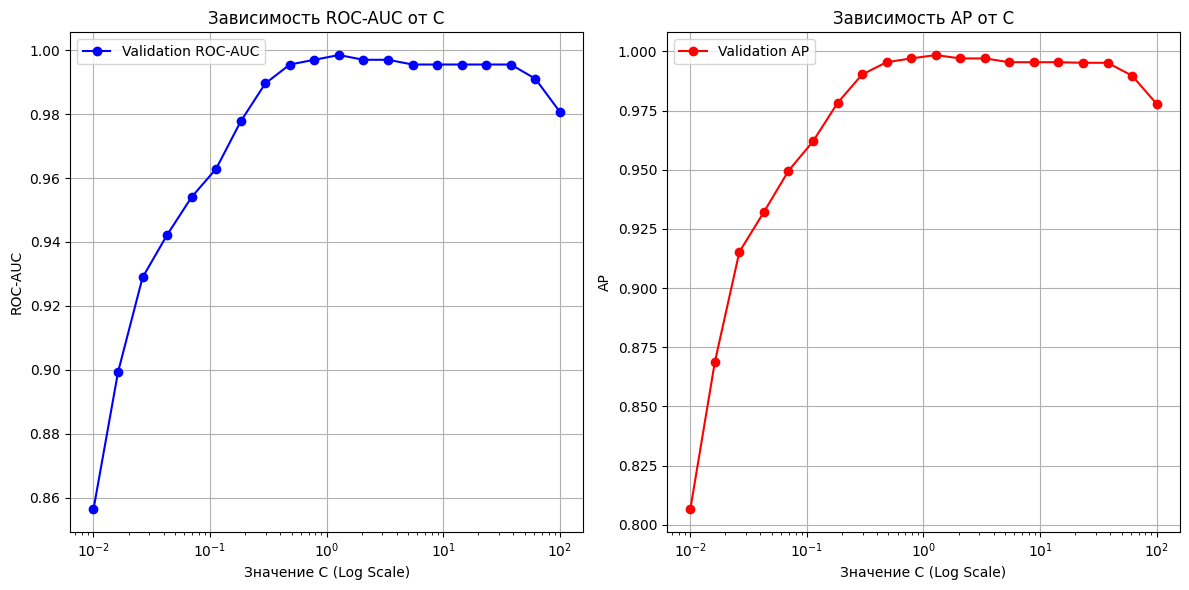

In [ ]:
model = SVC(probability=True, kernel='linear', random_state=42)
quality_by_C(X_train, X_val, y_train, y_val, model, param_range=(-2, 2))

**Вопрос.** Насколько похоже поведение зависимости качества модели от параметра $С$ по мере увеличения значения параметра?

**Ответ.** На четырёх признаках обе модели заметно улучшаются при переходе от очень малых C к умеренным. У логистической регрессии кривые затем почти выходят на плато, у SVM на правом краю виден спад. Значения C на максимумах различаются. Эти кривые описывают выбранную validation, а не универсальное правило выбора C.

### Визуализация разделяющей границы SVM

Опорные векторы имеют ненулевые коэффициенты в двойственном представлении SVM и определяют разделяющую функцию. Покажем их синими окружностями на искусственной двумерной выборке.

In [ ]:
def plot_svm_boundary(X, y, model, title=""):
    model.fit(X, y)
    # Создаём сетку для визуализации
    xx = np.linspace(np.min(X[:, 0]), np.max(X[:, 0]), 100)
    yy = np.linspace(np.min(X[:, 1]), np.max(X[:, 1]), 100)
    XX, YY = np.meshgrid(xx, yy)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = model.decision_function(xy).reshape(XX.shape)

    # Визуализация
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolors='k', label='Данные')
    plt.contour(XX, YY, Z, levels=[0], colors='black', linestyles='dashed', linewidths=2)
    plt.contour(XX, YY, Z, levels=[-1, 1], colors='gray', linestyles='solid', linewidths=1)
    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                s=200, facecolors='none', edgecolors='blue', linewidths=2, label='Опорные векторы')
    plt.xlabel('Признак 1 (X₁)')
    plt.ylabel('Признак 2 (X₂)')
    plt.title(title)
    plt.legend()
    plt.grid(True)

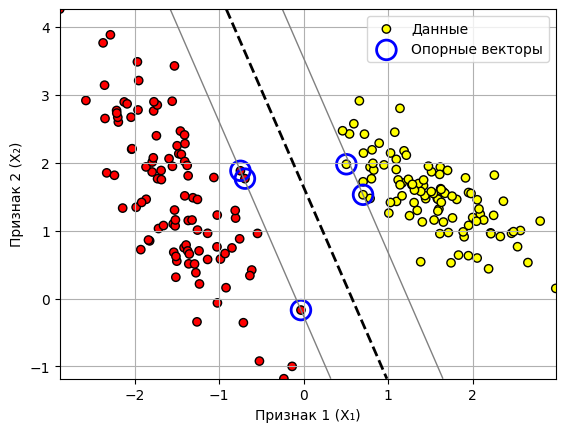

In [ ]:
X_sintetic, y_sintetic = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=56
)

plot_svm_boundary(X_sintetic, y_sintetic, model)

Синими окружностями отмечены опорные векторы. Пунктир показывает разделяющую границу, серые линии соответствуют значениям решающей функции −1 и 1. Рисунок показывает расположение этих объектов, но сам по себе не является экспериментом с их удалением.

### Влияние параметра $C$ на разделяющую границу

Вернёмся к датасету `wine` и посмотрим, как параметр $С$ влияет на разделяющую границу.

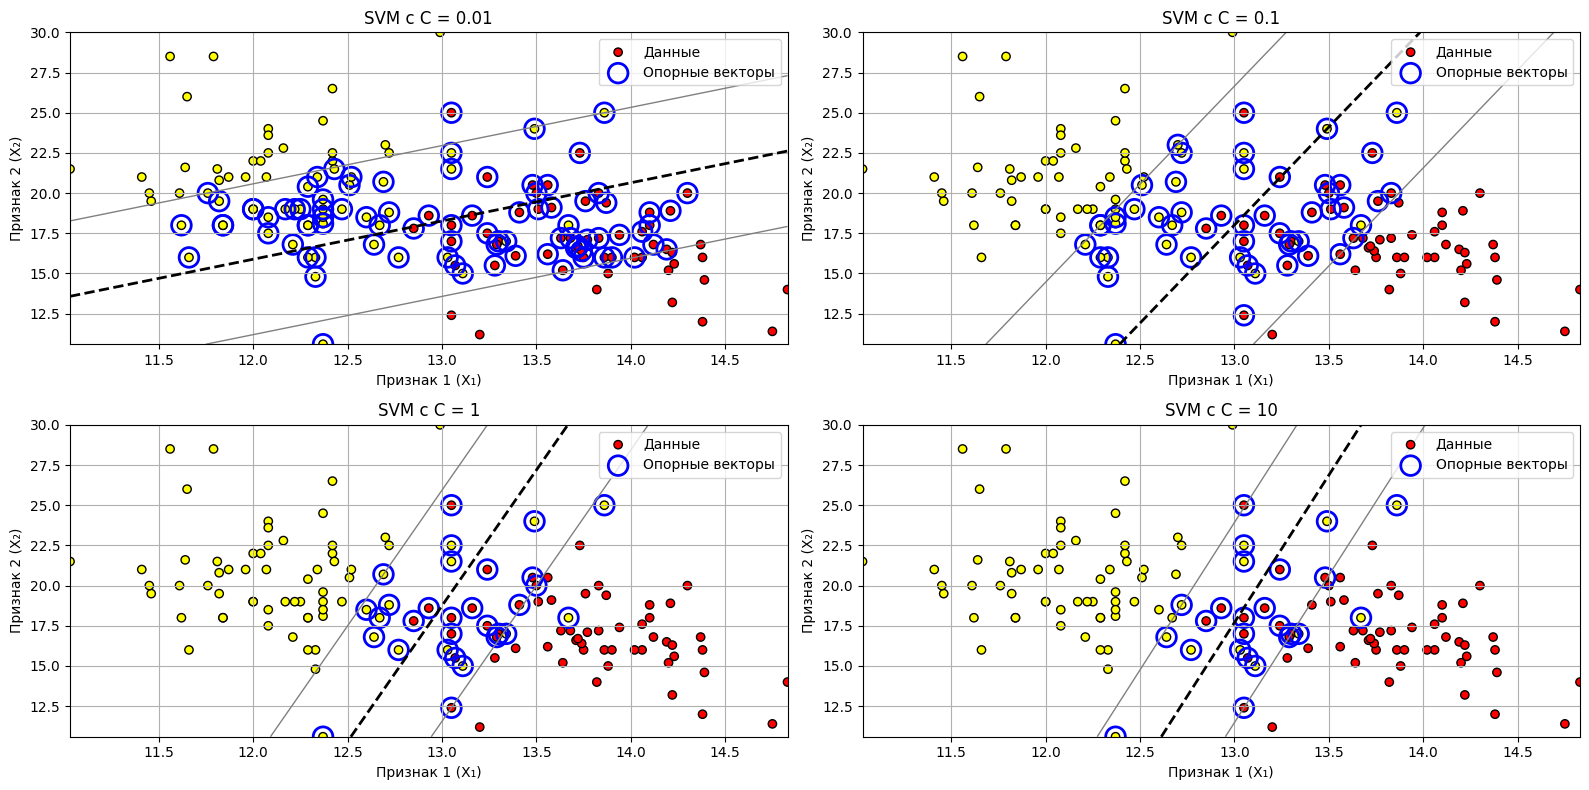

In [ ]:
C_values = [0.01, 0.1, 1, 10]

plt.figure(figsize=(16, 8))
for i, C in enumerate(C_values):
    plt.subplot(2, 2, i + 1)
    model = SVC(kernel='linear', C=C)
    plot_svm_boundary(X[:, top2_idx], y, model, title=f"SVM с C = {C}")
plt.tight_layout()
plt.show()

При малом C штраф за нарушения отступа относительно слабее. При большом C их суммарная величина сильнее влияет на целевую функцию. Сравни положение границы и число опорных векторов на рисунках. Для линейного ядра граница при любом C остаётся прямой, а число опорных векторов не обязано меняться монотонно.

## Калибровка вероятностей

Некоторые классификаторы возвращают оценки вероятностей, другие только метки или непрерывные оценки классов. Для хорошо откалиброванной модели среди объектов с прогнозом около 0,8 доля положительных меток должна быть близка к 80%.

Калибровочная кривая группирует прогнозы по интервалам. По оси X откладывают среднюю предсказанную вероятность внутри группы, по оси Y долю положительных меток. Диагональ соответствует их совпадению. На конечной выборке особенно малые группы дают неточную оценку этой доли.

### Сигмоидная калибровка Платта (Platt Scaling)



Метод Платта — это способ калибровки, при котором выход модели преобразуется в вероятность с помощью логистической функции. Метод особенно полезен для моделей, не выдающих вероятности напрямую, например SVM.

Формула:
$$P(y = 1 \mid x) = \displaystyle\frac{1}{1 + \exp(A f(x) + B)},$$


- где $A$ и $B$ — параметры, подбираемые на отдельной калибровочной выборке или на OOF-прогнозах;
- $f(x)$ — непрерывная оценка модели, например `decision_function` у SVM. Она не обязана быть логитом.

### Изотоническая регрессия

Изотоническая регрессия — более гибкий метод, который не предполагает конкретной формы калибровочной функции. Единственное ограничение: функция должна быть монотонно неубывающей.

Математически задача выглядит так: дан вектор предсказаний $ f(x_1), \dots, f(x_n)$ и соответствующие бинарные метки $y_1, \dots, y_n$. Требуется найти монотонную функцию $g(\cdot)$, минимизирующую среднеквадратичную ошибку:

$$\displaystyle\min_{g \text{ монотонна}} \sum_{i=1}^{n} \left( g(f(x_i)) - y_i \right)^2.$$

Изотоническая регрессия оценивает монотонную зависимость вероятности от скора. Её гибкость требует достаточного объёма калибровочных данных. При малом числе примеров ступенчатая функция может подстроиться под шум.

### Метрики эффективности калибровки



#### Log Loss

Основная метрика для вероятностных моделей классификации. Она измеряет, насколько предсказанные вероятности близки к истине.

Интуиция:

- чем ближе предсказанная вероятность к правильному классу, тем меньше штраф;
- если модель уверенно ошибается (например, предсказала 0,99, а правильный класс — 0), логарифмическая потеря резко возрастает;
- поэтому Log Loss чувствительна к неоткалиброванным предсказаниям — и именно это делает её особенно полезной.

Формула:

$$\text{Log Loss} = -\displaystyle \frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right],$$


- где $n$ — число объектов;
- $y_i \in \{0,~1\} $ — истинная метка;
- $p_i \in [0,~1]$ — предсказанная моделью вероятность класса 1.

#### Brier Score

Альтернативная метрика, оценивает среднеквадратичную ошибку между предсказанной вероятностью и фактическим исходом.

Формула:

$$\text{Brier} = \displaystyle\frac{1}{n} \sum_{i=1}^{n} \left( p_i - y_i \right)^2.$$

Brier Score менее чувствительна к экстремальным ошибкам.

### Применение методов калибровки к реальным данным

Для калибровки используем бинарную версию `delta_ailerons` из OpenML, ID 803. Признаки описывают состояние самолёта, исходная задача связана с изменением положения элеронов. В этой версии целевая переменная содержит две метки. Выведем соответствие меток числам 0 и 1, чтобы явно определить положительный класс.

In [ ]:
from sklearn.datasets import fetch_openml

dataset_info = ["delta_ailerons", 803]

data = fetch_openml(data_id=dataset_info[1], as_frame=True)
X = data.data
y = data.target
feature_names = data.feature_names
# Кодируем метки для бинарных вероятностных метрик.
encoder = LabelEncoder()
y = encoder.fit_transform(y.astype(str))
print(dict(enumerate(encoder.classes_)))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

{0: 'N', 1: 'P'}


In [ ]:
import plotly.express as px
from sklearn.calibration import calibration_curve

def plot_calibration_curve(X_train, y_train, X_test, y_test, model, title):
    # Получаем предсказанные вероятности для положительного класса
    prob_pred = model.predict_proba(X_test)[:, 1]

    # Рассчитываем калибровочные кривые
    prob_true_calib, prob_pred_calib = calibration_curve(
        y_test,
        prob_pred,
        n_bins=10,  # Количество бинов для калибровки
        strategy='quantile'  # Стратегия разбиения на бины
    )

    chart_df = pd.DataFrame({
        "Идеальный случай": prob_pred_calib,  # Идеальная диагональ y = x
        "predicted": prob_pred_calib,         # Средние предсказанные значения в бинах
        "Модель": prob_true_calib            # Реальные доли положительных классов
    })

    # Визуализация
    fig = px.line(
        data_frame=chart_df,
        markers=True,
        x="predicted",
        y=["Идеальный случай", "Модель"],
        labels={"value": "Доля положительных меток", "variable": "Легенда"}
    )
    fig.update_layout(
        title={"text": title, "y": 0.95, "x": 0.5},
        xaxis_title="Предсказанная вероятность",
        yaxis_title="Доля положительных меток",
    )
    # Одинаковые шкалы позволяют сравнить кривые до и после калибровки.
    fig.update_xaxes(range=[0, 1])
    fig.update_yaxes(range=[0, 1])
    fig.add_shape(type="line", x0=0, y0=0, x1=1, y1=1,
                  line=dict(color="#636EFA", dash="dash"))
    fig.show()

In [ ]:
# Отображение некалиброванного случая
logreg = LogisticRegression(max_iter=100)
logreg.fit(X_train, y_train)
plot_calibration_curve(X_train, y_train, X_test, y_test, logreg, "Некалиброванная модель")

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# Отображение — изотоническая калибровка
# Вызываем изотоническую калибровку
calibrated_logreg_iso = CalibratedClassifierCV(logreg, method = 'isotonic')
calibrated_logreg_iso.fit(X_train, y_train)
plot_calibration_curve(X_train, y_train, X_test, y_test, calibrated_logreg_iso, "Изотоническая калибровка")

In [ ]:
# Отображение — калибровка Платта
# Вызываем калибровку Платта
calibrated_logreg_log = CalibratedClassifierCV(logreg, method = 'sigmoid')
calibrated_logreg_log.fit(X_train, y_train)
plot_calibration_curve(X_train, y_train, X_test, y_test, calibrated_logreg_log, "Калибровка Платта")

In [ ]:
from sklearn.metrics import brier_score_loss, log_loss

# Делаем предсказания для обеих моделей
y_pred_proba_orig = logreg.predict_proba(X_test)[:,1]
y_pred_proba_calib_iso = calibrated_logreg_iso.predict_proba(X_test)[:,1]
y_pred_proba_calib_log = calibrated_logreg_log.predict_proba(X_test)[:,1]

# Создаём DataFrame с метриками
metrics_df = pd.DataFrame({
    'Модель': ['Логистическая регрессия', 'Изотоническая калибровка', 'Калибровка Платта'],
    'Brier Score': [
        brier_score_loss(y_test, y_pred_proba_orig),
        brier_score_loss(y_test, y_pred_proba_calib_iso),
        brier_score_loss(y_test, y_pred_proba_calib_log)
    ],
    'Log Loss': [
        log_loss(y_test, y_pred_proba_orig),
        log_loss(y_test, y_pred_proba_calib_iso),
        log_loss(y_test, y_pred_proba_calib_log)
    ],
    'AUC-ROC': [
        roc_auc_score(y_test, y_pred_proba_orig),
        roc_auc_score(y_test, y_pred_proba_calib_iso),
        roc_auc_score(y_test, y_pred_proba_calib_log)
    ]
}).round(3)


print(metrics_df)

                     Модель  Brier Score  Log Loss  AUC-ROC
0   Логистическая регрессия        0.236     0.665    0.963
1  Изотоническая калибровка        0.058     0.262    0.964
2         Калибровка Платта        0.060     0.225    0.964


Сравни Brier Score и Log Loss в таблице: для обеих метрик меньшее значение лучше. Калибровочные кривые показывают, в каких диапазонах прогнозы расходятся с наблюдаемой долей положительных меток. Эти метрики зависят и от калибровки, и от способности различать объекты.

`CalibratedClassifierCV` заново обучает базовые модели на фолдах и усредняет прогнозы откалиброванных моделей. Поэтому сравнение с единственной исходной моделью включает также эффект этого усреднения.

**Для преподавателя.** Исходные Brier Score и Log Loss равны примерно 0,236 и 0,665. После изотонической калибровки они составляют 0,058 и 0,262, после Платта 0,060 и 0,225. Оба метода улучшили обе метрики, но лучший метод зависит от метрики. ROC-AUC почти не изменился (около 0,964), то есть основное изменение касается вероятностной шкалы.

## Многоклассовая классификация

Во многих реальных задачах число классов может быть больше двух.  Например, в уже знакомом по прошлому семинару датасете `load_wine` и по семинару «Метрические алгоритмы» — в датасете `load_digits`.


Чтобы работать с такими данными, используются разные подходы к многоклассовой классификации. Наиболее популярные из них:
- **One-vs-Rest** — для каждого класса строится отдельный бинарный классификатор («розы vs все остальные»);
- **One-vs-One** — каждая пара классов соревнуется друг с другом («розы vs тюльпаны», «розы vs орхидеи»).

В этом разделе:
1. Реализуем оба подхода OvR и OvO на базе `LogisticRegression` из sklearn.
2. Сравним их по метрикам и построим сводную таблицу с результатами.
3. Визуализируем предсказания.

Затем ты оценишь, какой метод отработал лучше для каждого датасета, и решишь почему.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, classification_report, f1_score
import time
import pandas as pd
from sklearn.datasets import load_digits

# Создадим датафрейм с ключевыми метриками для сравнения
def train_and_compare_models(X_train, y_train, X_test, y_test):
    # Создаём базовую логистическую регрессию
    base_model = LogisticRegression(max_iter=10000)

    # One-vs-Rest-классификатор
    ovr = OneVsRestClassifier(base_model)
    start_time = time.time()
    ovr.fit(X_train, y_train)
    ovr_time = time.time() - start_time
    ovr_preds = ovr.predict(X_test)
    ovr_probs = ovr.predict_proba(X_test)

    # One-vs-One-классификатор
    ovo = OneVsOneClassifier(base_model)
    start_time = time.time()
    ovo.fit(X_train, y_train)
    ovo_time = time.time() - start_time
    ovo_preds = ovo.predict(X_test)

    # Результаты
    results = {
        "Метрика": [
            "Время обучения (сек.)",
            "Кол-во классификаторов",
            "Accuracy",
            "Macro F1"
        ],
        "OvR": [
            round(ovr_time, 4),
            len(ovr.estimators_),
            round(accuracy_score(y_test, ovr_preds), 4),
            round(f1_score(y_test, ovr_preds, average='macro'), 4)
        ],
        "OvO": [
            round(ovo_time, 4),
            len(ovo.estimators_),
            round(accuracy_score(y_test, ovo_preds), 4),
            round(f1_score(y_test, ovo_preds, average='macro'), 4)
        ]
    }

    results_df = pd.DataFrame(results)
    predictions = [ovr_preds, ovo_preds]

    return results_df, predictions

In [ ]:
# Так как у нас два датасета, создадим вспомогательную функцию для работы с ними
def load_and_split_dataset(loader, test_size=0.4, random_state=42):
    data = loader()
    X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=test_size, random_state=random_state)
    return {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "feature_names": getattr(data, "feature_names", None),
        "target_names": getattr(data, "target_names", None)
    }

# Список датасетов
datasets = {"wine": load_wine, "digits": load_digits}
splits = {name: load_and_split_dataset(loader) for name, loader in datasets.items()}

In [ ]:
for name, split in splits.items():
    print("============================================")
    print(f"Датасет {name}, кол-во классов: {np.unique(split['y_train']).size}")
    print("============================================")
    results = train_and_compare_models(split["X_train"], split["y_train"], split["X_test"], split["y_test"])[0]
    print(results)

Датасет wine, кол-во классов: 3


                  Метрика     OvR     OvO
0   Время обучения (сек.)  6.6667  1.1432
1  Кол-во классификаторов  3.0000  3.0000
2                Accuracy  0.9583  0.9444
3                Macro F1  0.9622  0.9495
Датасет digits, кол-во классов: 10


                  Метрика      OvR      OvO
0   Время обучения (сек.)   5.2802   5.8790
1  Кол-во классификаторов  10.0000  45.0000
2                Accuracy   0.9583   0.9861
3                Macro F1   0.9582   0.9859


### Задание 6  
Проанализируй результаты по следующим аспектам и сформулируй выводы.

1. Время обучения:
 - Как отличается время обучения между OvR и OvO на разных датасетах?
 - Почему время различается? Как влияет на это число классов и объём данных?
2. Количество классификаторов:
 - Сколько моделей обучается в каждом из подходов?
 - Как зависит это число от количества классов?
 - Какие практические выводы можно сделать из этого?
3. Качество моделей (Accuracy и Macro F1):
 - Как OvR и OvO справляются на разных датасетах?
 - Где каждая модель показывает лучшие результаты и почему?


#### Решение

OvR обучает K бинарных моделей, OvO обучает K(K−1)/2 моделей. Для Wine это 3 и 3, для Digits 10 и 45. Каждая модель OvO обучается только на двух классах, поэтому большее число моделей не обязательно означает большее время. В контрольном запуске OvO на Wine был быстрее. На Digits времена оказались близкими. На время также влияют сходимость оптимизации и нагрузка компьютера.

На Wine OvR лучше по Accuracy (0,958 против 0,944) и Macro F1 (0,962 против 0,950). На Digits лучше OvO: Accuracy 0,986 против 0,958, Macro F1 0,986 против 0,958. Победитель зависит от данных и настроек, а не только от числа классов.

### Анализ ошибок многоклассовой классификации

Посмотрим, как именно ошибалась каждая модель. Так как данные имеют высокую размерность, для визуализации удобно использовать PCA (Principal Component Analysis). Это метод главных компонент, который снижает размерность до 2D или 3D, сохраняя максимально возможную дисперсию среди линейных ортогональных проекций той же размерности.

Напомним, как работает PCA:
- PC1 (первая компонента) — это направление наибольшей изменчивости в данных (максимальная дисперсия).
- PC2 (вторая компонента) — это направление наибольшей оставшейся изменчивости, ортогональное к PC1.

Таким образом, в проекции на плоскость PC1–PC2 можно:
- увидеть, как объекты группируются по классам;
- посмотреть расположение ошибок в проекции. Часть различий между объектами при этом теряется.

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def plot_predictions(X_test, y_test, ovr_preds, ovo_preds, class_names):
    # PCA для снижения размерности
    pca = PCA(n_components=2)
    X_test_pca = pca.fit_transform(X_test)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    # Истинные метки
    scatter_true = ax[0].scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap='viridis', vmin=0, vmax=len(class_names)-1, alpha=0.4)
    ax[0].set_title('Данные')
    handles, _ = scatter_true.legend_elements()
    ax[0].legend(handles, class_names)
    ax[0].grid(True, alpha=0.3)

    # Предсказания
    predictions_info = [(ovr_preds, 'Предсказания OvR', 1), (ovo_preds, 'Предсказания OvO', 2)]
    for preds, title, i in predictions_info:
        mask_correct = (preds == y_test)
        mask_wrong = ~mask_correct
        ax[i].scatter(X_test_pca[mask_correct, 0], X_test_pca[mask_correct, 1], c=y_test[mask_correct], cmap='viridis', vmin=0, vmax=len(class_names)-1, alpha=0.4, marker='o')
        ax[i].scatter(X_test_pca[mask_wrong, 0], X_test_pca[mask_wrong, 1], c='red', alpha=0.7, marker='X', s=70)
        ax[i].set_title(title)
        ax[i].grid(True, alpha=0.3)
    for axis in ax:
        axis.set_xlabel('PC1')
        axis.set_ylabel('PC2')

    # Общая легенда
    correct_patch = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=10, label='Correct')
    wrong_patch = plt.Line2D([0], [0], marker='X', color='w', markerfacecolor='red', markersize=10, label='Wrong')
    fig.legend(handles=[correct_patch, wrong_patch], loc='lower center', ncol=2)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15)
    plt.show()

Датасет wine, кол-во классов: 3


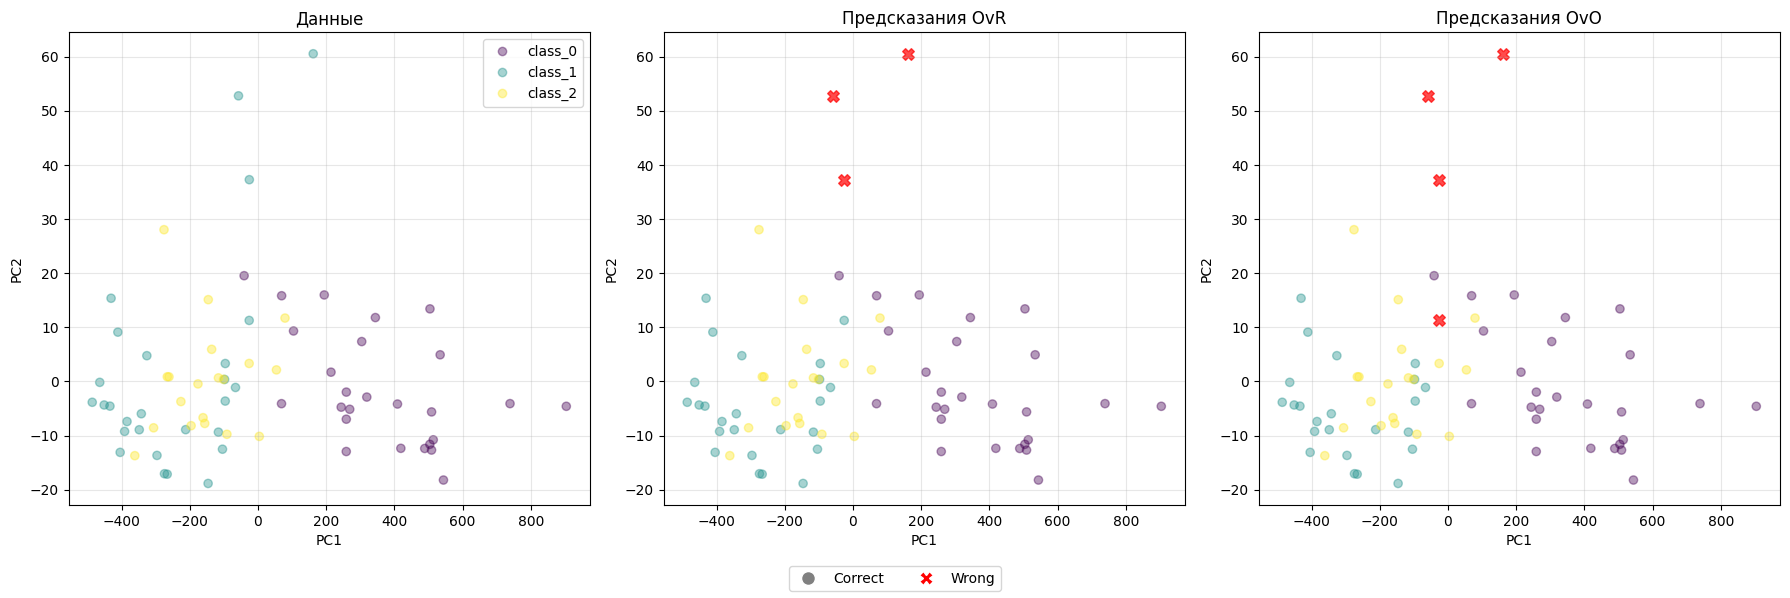

Датасет digits, кол-во классов: 10


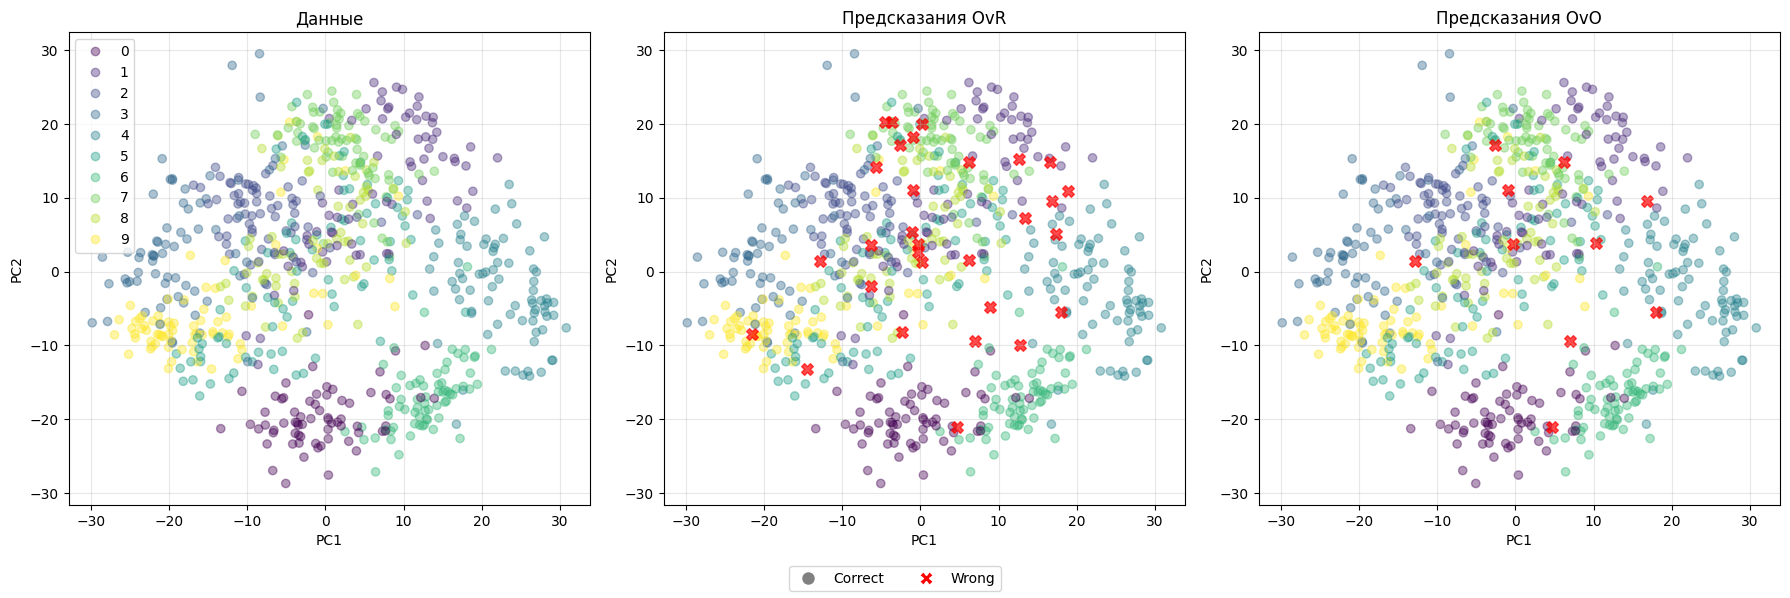

In [ ]:
for name, split in splits.items():
    print(f"Датасет {name}, кол-во классов: {np.unique(split['y_train']).size}")
    X_test, y_test = split["X_test"], split["y_test"]
    ovr_preds, ovo_preds = train_and_compare_models(split["X_train"], split["y_train"], split["X_test"], split["y_test"])[1]
    class_names = split["target_names"]
    plot_predictions(X_test, y_test, ovr_preds, ovo_preds, class_names)

### Задание 7  

Посмотри, где расположены ошибочно классифицированные объекты в двумерной PCA-проекции. Сопоставь рисунки с Accuracy и Macro F1. Какие различия видны между OvR и OvO? Какие выводы о работе в исходном пространстве признаков нельзя сделать только по этой проекции?

#### Решение

На Wine у OvR три ошибки из 72 объектов, у OvO четыре. На Digits у OvR 30 ошибок из 719, у OvO 10. Это согласуется с таблицами Accuracy. Красные крестики обозначают ошибки, а цвет обычных точек соответствует истинному классу.

Ошибки встречаются и в областях перекрытия классов на рисунке, и вдали от них. PCA сохраняет только два направления вариации, поэтому положение точки в этой проекции не объясняет причину ошибки и не доказывает переобучения. Модели обучались на исходных признаках.

## Теперь ты умеешь
- Использовать логистическую регрессию и SVM в обучении модели и визуализировать разделяющую границу.
- Калибровать предсказания при помощи методов Платта и изотонической регрессии.
- Использовать методы OvR и OvO для многоклассовой классификации.

# Обратная связь по семинару для очной магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cmt6wf8lr000s0ds6c5a0gedj) или QR-коду ниже.

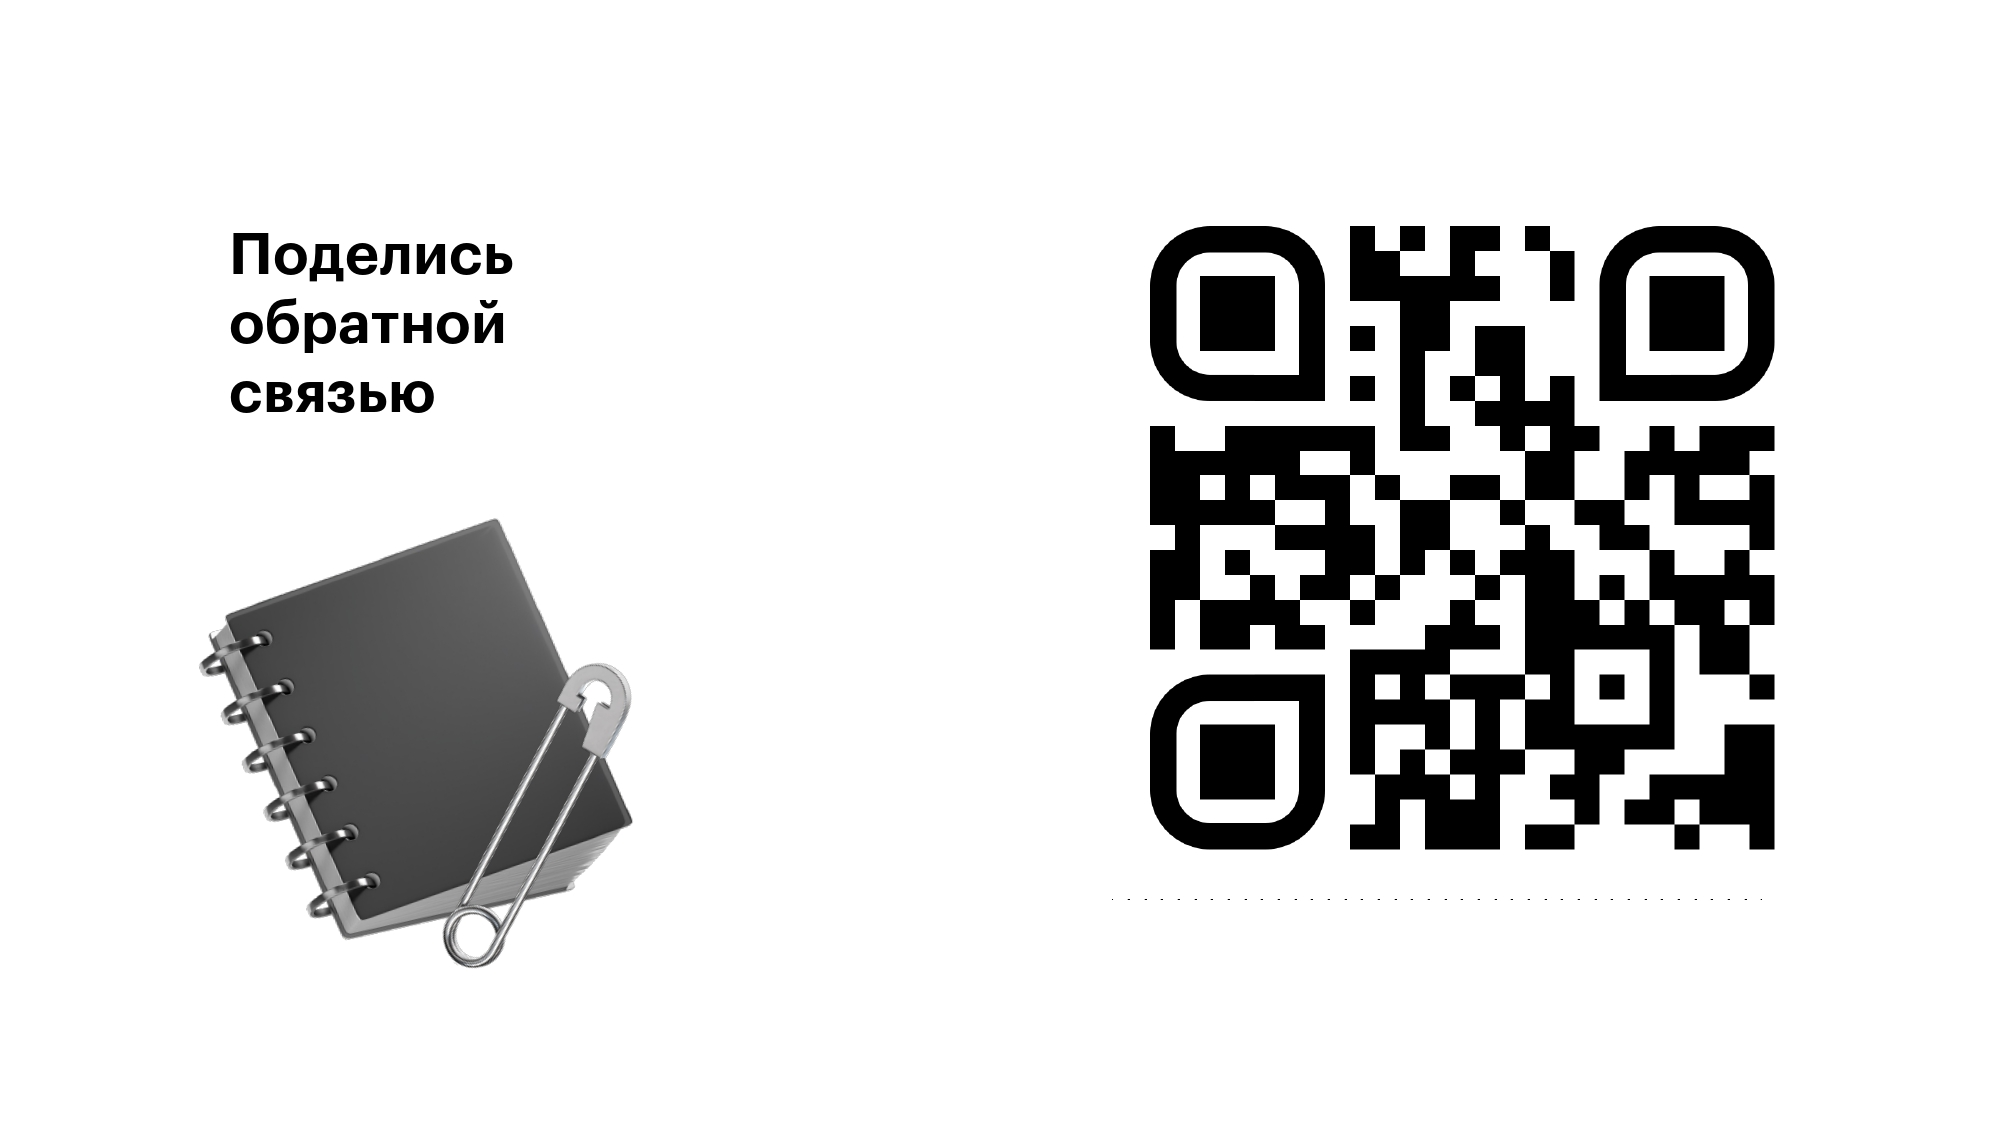

# Обратная связь по семинару для онлайн-магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cms63133e00440dribvbmail8) или QR-коду ниже.

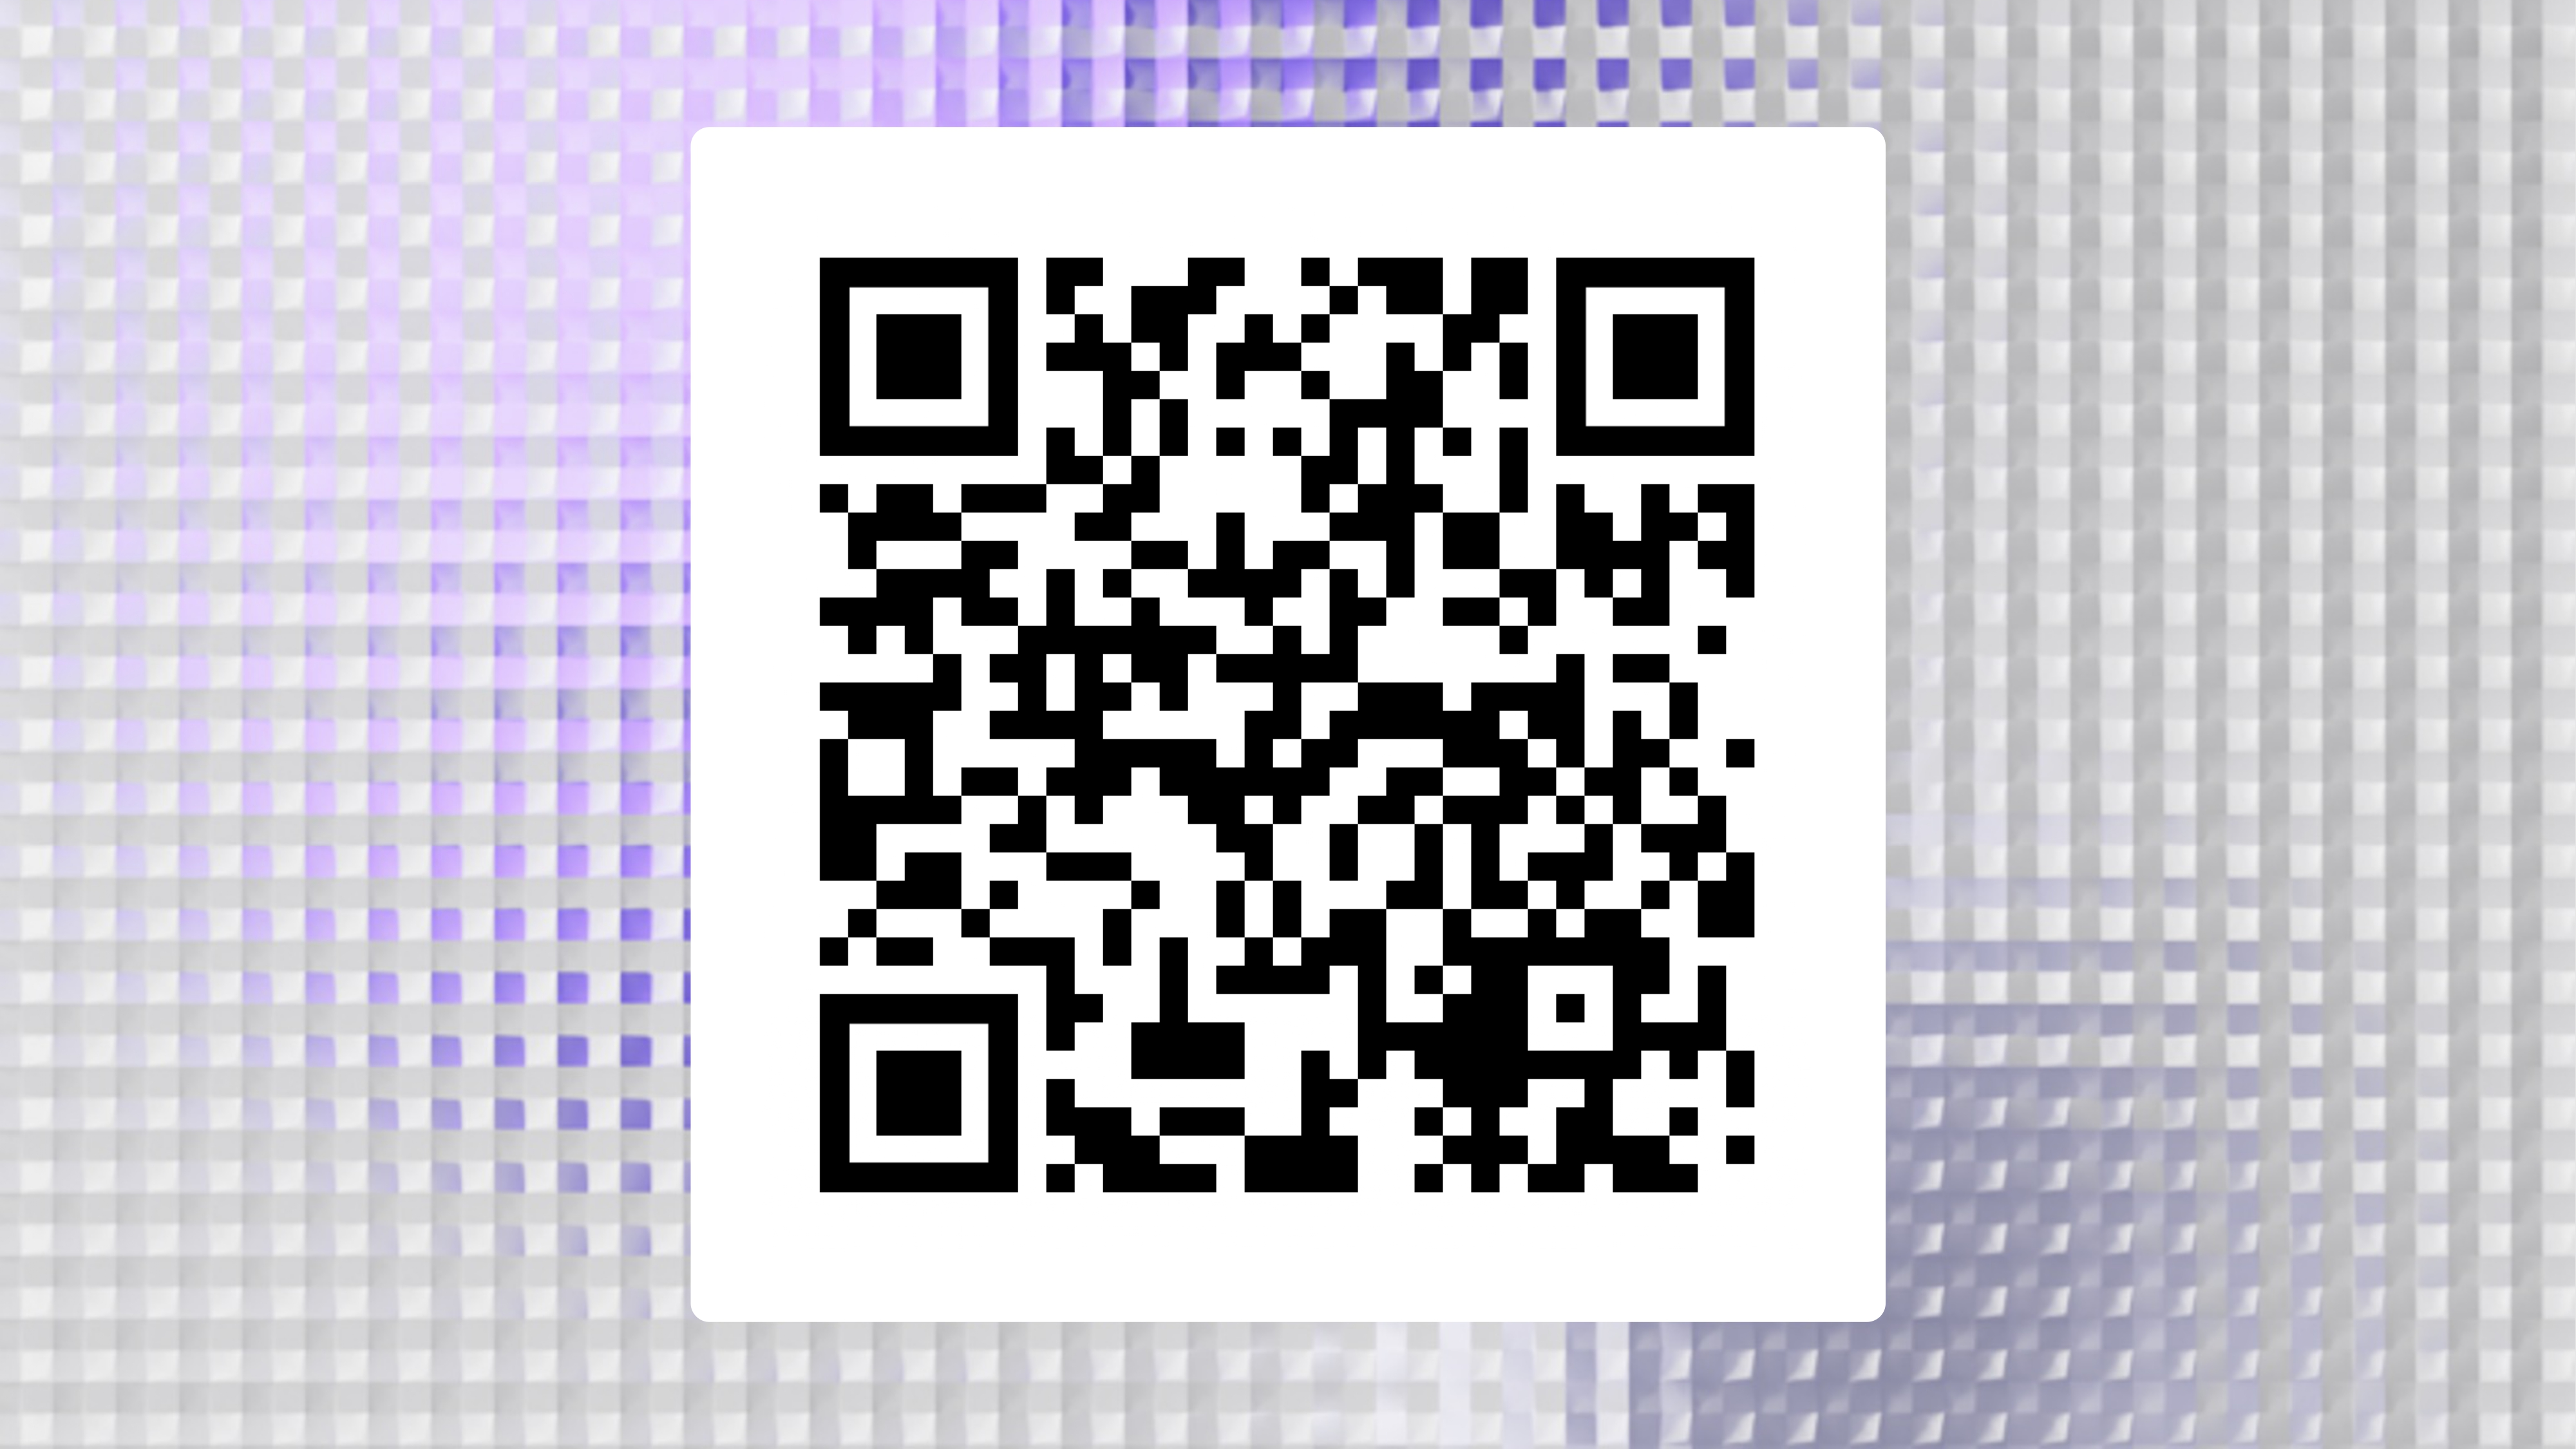